# Ghép ảnh toàn cảnh: so sánh SIFT, ORB và SURF

Notebook hiện thực pipeline của mục 2.2: **nạp ảnh → trích xuất đặc trưng → matching → homography với RANSAC → căn chỉnh → feather blending → đánh giá**. Ba phương pháp dùng cùng ảnh đầu vào và cùng các bước xử lý sau trích xuất đặc trưng. Khác biệt cần thiết là phép đo khoảng cách descriptor: L2 cho SIFT/SURF, Hamming cho ORB.

**Đầu ra quan sát được:** ảnh đầu vào; keypoint trên từng ảnh; match sau ratio test và inlier sau RANSAC cho từng cặp kề nhau; ảnh overlay kiểm tra căn chỉnh; ảnh ghép trước/sau blending; panorama cuối; bảng số liệu. 

Cần `opencv-python`, `mahotas`, `numpy` và `IPython`. **SURF** được tính bằng [`mahotas.features.surf`](https://mahotas.readthedocs.io/en/latest/surf.html). [Bản OpenCV dựng sẵn](https://github.com/opencv/opencv-python#why-the-packages-do-not-include-non-free-algorithms) trên máy không bật thuật toán SURF, nên notebook dùng triển khai SURF của Mahotas; các bước matching, homography và ghép ảnh vẫn dùng chung pipeline.


## 1. Dữ liệu và cấu hình

`BK-H6-imgs` dùng đủ 4 ảnh. Bộ `company` dùng 4 ảnh đầu trong 5 ảnh hiện có để đúng phạm vi 3–4 ảnh của đề. Ảnh được sắp theo tên file, tương ứng thứ tự chụp/góc nhìn. Ảnh BK-H6 được giảm cạnh dài xuống 900 px để thời gian xử lý và kích thước notebook hợp lý. Trước khi tìm đặc trưng, ảnh được chiếu lên mặt trụ để hạn chế méo ở góc nhìn rộng. Cùng phép chiếu được dùng cho SIFT, ORB và SURF; tiêu cự được ước lượng bằng `1.2 × chiều rộng ảnh` vì bộ ảnh không có dữ liệu hiệu chuẩn máy ảnh.


Python: c:\Users\LENOVO\AppData\Local\Programs\Python\Python312\python.exe | OpenCV: 5.0.0 | Mahotas: 1.4.19


**Ảnh đầu vào — BK-H6**

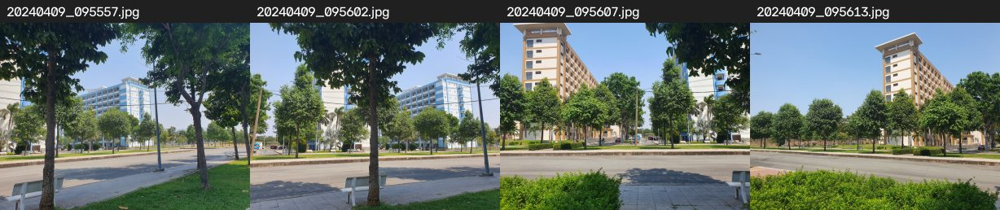

**Ảnh đầu vào — company**

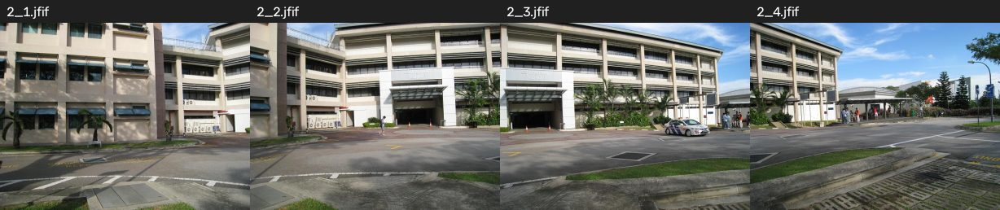

In [20]:
import sys
from pathlib import Path
from time import perf_counter

import cv2 as cv
import mahotas
from mahotas.features import surf as mh_surf
import numpy as np
from IPython.display import Image as NotebookImage, Markdown, display

print('Python:', sys.executable, '| OpenCV:', cv.__version__, '| Mahotas:', mahotas.__version__)

ROOT = Path.cwd()
DATASETS = {
    "BK-H6": sorted((ROOT / "BK-H6-imgs").glob("*.jpg")),
    "company": sorted((ROOT / "company").glob("*.jfif"))[:4],
}
CONFIG = {
    "max_side": 900,
    "nfeatures": 2500,
    "ratio": 0.78,
    "ransac_px": 4.0,
    "focal_ratio": 1.2,
}


def load_images(paths, max_side):
    images = []
    for path in paths:
        image = cv.imread(str(path))
        scale = min(1.0, max_side / max(image.shape[:2]))
        images.append(cv.resize(image, None, fx=scale, fy=scale, interpolation=cv.INTER_AREA)
                      if scale < 1 else image)
    return images


def cylindrical_project(image, focal_ratio):
    h, w = image.shape[:2]
    focal = w * focal_ratio
    y, x = np.indices((h, w), dtype=np.float32)
    theta = (x - w / 2) / focal
    map_x = focal * np.tan(theta) + w / 2
    map_y = (y - h / 2) / np.cos(theta) + h / 2
    projected = cv.remap(image, map_x, map_y, cv.INTER_LINEAR)
    valid = cv.remap(np.full((h, w), 255, np.uint8), map_x, map_y, cv.INTER_NEAREST)
    return projected, valid


def show_image(title, image, max_width=1400):
    # Hiển thị JPEG gọn để output nằm ngay trong file notebook.
    display(Markdown(f"**{title}**"))
    scale = min(1.0, max_width / image.shape[1])
    preview = cv.resize(image, None, fx=scale, fy=scale, interpolation=cv.INTER_AREA) if scale < 1 else image
    encoded = cv.imencode(".jpg", preview, [cv.IMWRITE_JPEG_QUALITY, 82])[1]
    display(NotebookImage(data=encoded.tobytes()))


def strip(images, labels, tile_height=230):
    # Ghép các ảnh cùng chiều cao và ghi nhãn để so sánh trực tiếp.
    tiles = []
    for image, label in zip(images, labels):
        width = round(image.shape[1] * tile_height / image.shape[0])
        tile = cv.resize(image, (width, tile_height), interpolation=cv.INTER_AREA)
        tile = cv.copyMakeBorder(tile, 28, 0, 0, 0, cv.BORDER_CONSTANT, value=(32, 32, 32))
        cv.putText(tile, label, (8, 20), cv.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1, cv.LINE_AA)
        tiles.append(tile)
    return cv.hconcat(tiles)


images_by_set = {name: load_images(paths, CONFIG["max_side"]) for name, paths in DATASETS.items()}
for name, images in images_by_set.items():
    labels = [path.name for path in DATASETS[name]]
    show_image(f"Ảnh đầu vào — {name}", strip(images, labels))


## 2. Trích xuất đặc trưng

SIFT và ORB dùng OpenCV; SURF dùng Mahotas. Hàm trích xuất thống nhất đầu ra thành danh sách `cv.KeyPoint` và mảng descriptor để toàn bộ các bước sau dùng chung. Descriptor SURF của Mahotas có **64 giá trị thực**; vì vậy SURF dùng khoảng cách L2 tương tự SIFT. Mask của phép chiếu mặt trụ loại các điểm ở vùng ảnh trống. Ảnh minh họa chỉ vẽ tối đa 180 keypoint mạnh nhất; các bước ghép dùng toàn bộ keypoint đã phát hiện.


In [21]:
def extract_features(images, masks, method, nfeatures):
    gray_images = [cv.cvtColor(image, cv.COLOR_BGR2GRAY) for image in images]
    if method == "SURF":
        features = []
        for gray, mask in zip(gray_images, masks):
            # Mahotas trả mỗi điểm theo dạng (y, x, scale, score, laplacian, angle, 64 descriptor).
            points = mh_surf.surf(gray, max_points=nfeatures)
            y, x = np.rint(points[:, 0]).astype(int), np.rint(points[:, 1]).astype(int)
            points = points[mask[y, x] > 0]
            keypoints = [cv.KeyPoint(float(p[1]), float(p[0]), float(p[2]),
                                     float(np.degrees(p[5])), float(p[3])) for p in points]
            features.append((keypoints, points[:, 6:].astype(np.float32)))
    else:
        detector = cv.SIFT_create(nfeatures=nfeatures) if method == "SIFT" else cv.ORB_create(nfeatures=nfeatures)
        features = [detector.detectAndCompute(gray, mask) for gray, mask in zip(gray_images, masks)]
    keypoints, descriptors = zip(*features)
    return list(keypoints), list(descriptors)


def keypoint_preview(image, keypoints,):
    visible = sorted(keypoints, key=lambda point: point.response, reverse=True)[:]
    return cv.drawKeypoints(image, visible, None, None,
                            flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)


## 3. Matching và ước lượng homography

Chỉ ghép các cặp kề nhau `(0,1), (1,2), ...`. BFMatcher tìm hai ứng viên gần nhất; ratio test giữ cặp có ứng viên tốt nhất nổi bật hơn ứng viên thứ hai. Khoảng cách **L2** phù hợp với descriptor SIFT và SURF dạng số thực; **Hamming** đếm bit khác nhau của ORB mặc định. RANSAC tiếp tục loại các match không nhất quán về mặt hình học. Ở đây `H[i]` biến đổi tọa độ từ ảnh `i` sang ảnh `i+1`.


In [22]:
def match_and_estimate(keypoints, descriptors, method, ratio, ransac_px):
    norm = cv.NORM_HAMMING if method == "ORB" else cv.NORM_L2
    matcher = cv.BFMatcher(norm, crossCheck=False)
    pair_results = []

    for i in range(len(descriptors) - 1):
        neighbors = matcher.knnMatch(descriptors[i], descriptors[i + 1], k=2)
        # Ratio test loại các match có hai ứng viên gần như tương đương.
        good = []
        for pair in neighbors:
            if len(pair) == 2:
                best, second = pair
                if best.distance < ratio * second.distance:
                    good.append(best)
        src = np.float32([keypoints[i][m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
        dst = np.float32([keypoints[i + 1][m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
        H, inlier_mask = cv.findHomography(src, dst, cv.RANSAC, ransac_px)
        inliers = inlier_mask.ravel().astype(bool)
        projected = cv.perspectiveTransform(src, H)
        errors = np.linalg.norm(projected[:, 0] - dst[:, 0], axis=1)
        pair_results.append({
            "matches": good,
            "inliers": inliers,
            "H": H,
            "median_error_px": float(np.median(errors[inliers])),
        })
    return pair_results


def match_preview(images, keypoints, pair_result, i, inliers_only=False, limit=60):
    matches = pair_result["matches"]
    if inliers_only:
        matches = [m for m, keep in zip(matches, pair_result["inliers"]) if keep]
    matches = sorted(matches, key=lambda m: m.distance)[:limit]
    return cv.drawMatches(images[i], keypoints[i], images[i + 1], keypoints[i + 1],
                          matches, None, flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)


## 4. Căn chỉnh và blending

Ảnh gần giữa bộ là hệ tọa độ tham chiếu. Các homography giữa ảnh kề nhau được nhân nối tiếp để đưa mọi ảnh về cùng hệ tọa độ. Sau khi warp, **mask** xác định pixel nào thực sự có ảnh; không dùng màu đen làm dấu hiệu vùng rỗng vì ảnh gốc cũng có thể chứa pixel đen. Trong vùng chồng lấn, feather blending gán trọng số lớn hơn cho pixel ở xa mép ảnh, rồi chuẩn hóa tổng trọng số. Ảnh ghép trung bình đều được giữ để đối chiếu với blending.


In [23]:
def warp_and_blend(images, source_masks, pair_results):
    count = len(images)
    anchor = count // 2
    transforms = [None] * count
    transforms[anchor] = np.eye(3)

    # H[i] đi từ ảnh i sang i+1; nhân nối tiếp để đến ảnh tham chiếu.
    for i in range(anchor - 1, -1, -1):
        transforms[i] = transforms[i + 1] @ pair_results[i]["H"]
    for i in range(anchor + 1, count):
        transforms[i] = transforms[i - 1] @ np.linalg.inv(pair_results[i - 1]["H"])

    corners = []
    for image, H in zip(images, transforms):
        h, w = image.shape[:2]
        box = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
        corners.append(cv.perspectiveTransform(box, H).reshape(-1, 2))
    all_corners = np.vstack(corners)
    x0, y0 = np.floor(all_corners.min(axis=0)).astype(int)
    x1, y1 = np.ceil(all_corners.max(axis=0)).astype(int)
    translation = np.array([[1, 0, -x0], [0, 1, -y0], [0, 0, 1]], dtype=float)
    canvas_size = (int(x1 - x0), int(y1 - y0))

    height, width = canvas_size[1], canvas_size[0]
    average_sum = np.zeros((height, width, 3), np.float32)
    feather_sum = np.zeros_like(average_sum)
    count_map = np.zeros((height, width), np.uint8)
    weight_sum = np.zeros((height, width), np.float32)
    for image, source_mask, H in zip(images, source_masks, transforms):
        transform = translation @ H
        warped = cv.warpPerspective(image, transform, canvas_size)
        mask = cv.warpPerspective(source_mask, transform, canvas_size) > 0
        weights = np.maximum(cv.distanceTransform(mask.astype(np.uint8), cv.DIST_L2, 3), 1) * mask
        average_sum += warped * mask[..., None]
        feather_sum += warped * weights[..., None]
        count_map += mask.astype(np.uint8)
        weight_sum += weights

    # Cùng mask dùng cho cả ảnh trung bình đều và feather blending.
    average = average_sum / np.maximum(count_map[..., None], 1)
    feather = feather_sum / np.maximum(weight_sum[..., None], 1)

    # Bỏ phần canvas hoàn toàn trống; giữ nguyên vùng có dữ liệu để không mất cảnh.
    x, y, w, h = cv.boundingRect((count_map > 0).astype(np.uint8))
    crop = np.s_[y:y + h, x:x + w]
    coverage = cv.applyColorMap((count_map[crop] * 60).astype(np.uint8), cv.COLORMAP_TURBO)
    coverage[count_map[crop] == 0] = 0
    return {
        "panorama": np.uint8(np.clip(feather[crop], 0, 255)),
        "average": np.uint8(np.clip(average[crop], 0, 255)),
        "coverage": coverage,
        "crop": crop,
    }


def pair_overlay(images, pair_result, i):
    # Chồng ảnh i lên ảnh i+1 để nhìn các cạnh bị lệch/bóng đôi.
    h, w = images[i + 1].shape[:2]
    aligned = cv.warpPerspective(images[i], pair_result["H"], (w, h))
    mask = cv.warpPerspective(np.full(images[i].shape[:2], 255, np.uint8),
                              pair_result["H"], (w, h)) > 0
    overlay = images[i + 1].copy()
    overlay[mask] = cv.addWeighted(aligned[mask], 0.5, images[i + 1][mask], 0.5, 0)
    return overlay


## 5. Hàm `stitch` và chạy thực nghiệm

Một lời gọi `stitch(images, method, config)` trả về panorama **cùng toàn bộ kết quả trung gian và metrics**. Vì vậy các cell sau có thể quan sát từng bước dù chỉ gọi một hàm cho mỗi phương pháp. Cả ba phương pháp dùng cùng ảnh, phép chiếu mặt trụ, tỉ lệ thu nhỏ, ratio test, RANSAC, phép warp và feather blending. Thời gian tính từ lúc tiền xử lý đến panorama cuối.


Đã chạy xong 3 phương pháp trên 2 bộ ảnh.

**Ảnh sau chiếu mặt trụ — BK-H6**

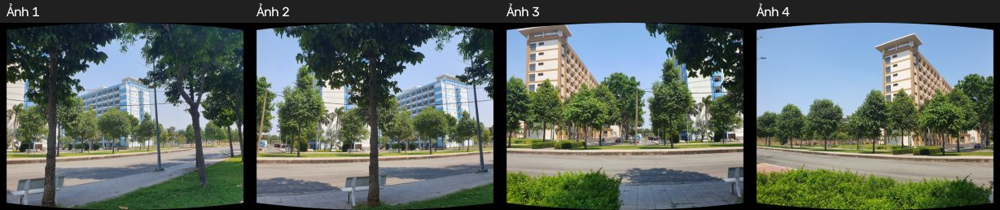

**Ảnh sau chiếu mặt trụ — company**

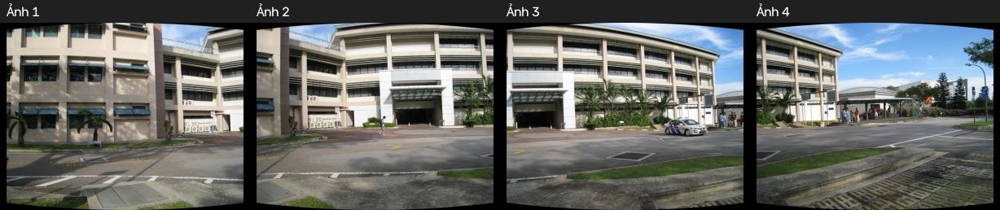

In [24]:
def stitch(images, feature_method, config):
    started = perf_counter()
    projected = [cylindrical_project(image, config["focal_ratio"]) for image in images]
    projected_images = [item[0] for item in projected]
    source_masks = [item[1] for item in projected]
    keypoints, descriptors = extract_features(projected_images, source_masks,
                                              feature_method, config["nfeatures"])
    feature_seconds = perf_counter() - started
    pairs = match_and_estimate(keypoints, descriptors, feature_method,
                               config["ratio"], config["ransac_px"])
    geometry_seconds = perf_counter() - started - feature_seconds
    composite = warp_and_blend(projected_images, source_masks, pairs)
    total_seconds = perf_counter() - started
    return {
        "method": feature_method,
        "images": projected_images,
        "keypoints": keypoints,
        "descriptors": descriptors,
        "pairs": pairs,
        **composite,
        "metrics": {
            "keypoints": [len(points) for points in keypoints],
            "matches": [len(pair["matches"]) for pair in pairs],
            "inliers": [int(pair["inliers"].sum()) for pair in pairs],
            "median_error_px": [pair["median_error_px"] for pair in pairs],
            "feature_seconds": feature_seconds,
            "geometry_seconds": geometry_seconds,
            "total_seconds": total_seconds,
        },
    }


results = {
    name: {method: stitch(images, method, CONFIG) for method in ("SIFT", "ORB", "SURF")}
    for name, images in images_by_set.items()
}
display(Markdown("Đã chạy xong 3 phương pháp trên 2 bộ ảnh."))
for name, methods in results.items():
    projected = methods["SIFT"]["images"]
    show_image(f"Ảnh sau chiếu mặt trụ — {name}",
               strip(projected, [f"Ảnh {i+1}" for i in range(len(projected))]))


## 6. Quan sát keypoint

Ba hàng dưới đây dùng cùng các ảnh sau tiền xử lý: hàng SIFT, ORB và SURF. So sánh vị trí phân bố điểm, đặc biệt trên mặt tường ít hoa văn, cây lá và các cạnh công trình. Số lượng đầy đủ nằm ở bảng metrics phía cuối.


**BK-H6 — keypoint SIFT**

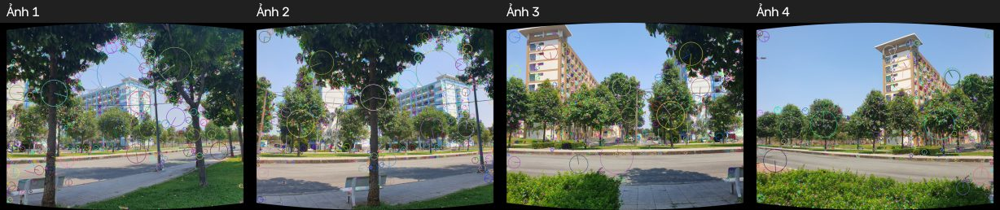

**BK-H6 — keypoint ORB**

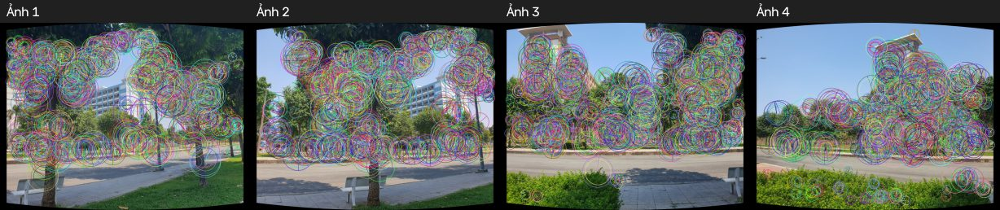

**BK-H6 — keypoint SURF**

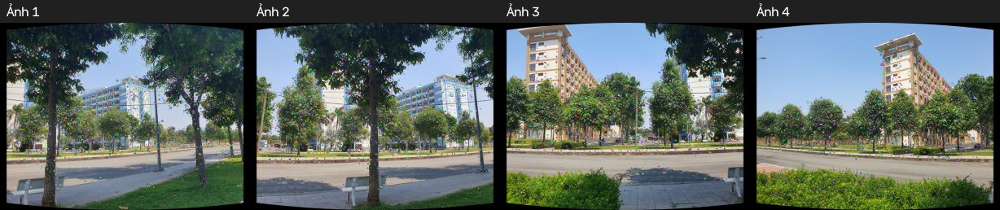

**company — keypoint SIFT**

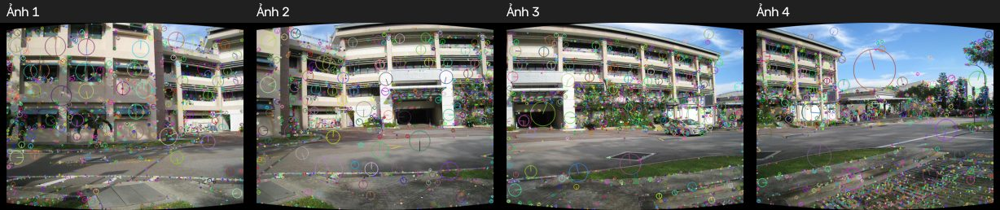

**company — keypoint ORB**

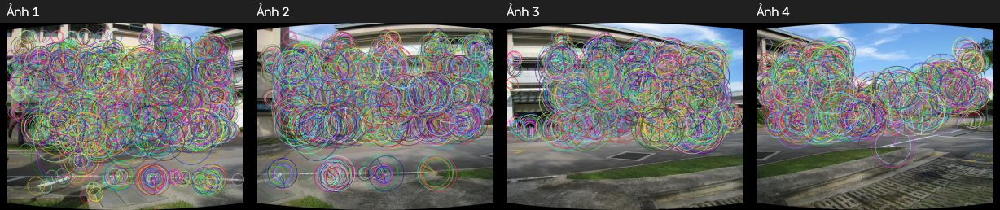

**company — keypoint SURF**

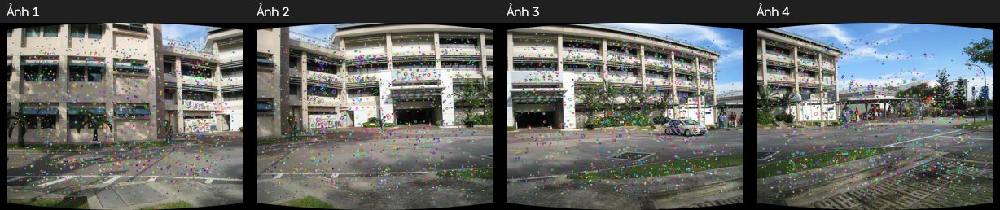

In [25]:
for name, methods in results.items():
    for method, result in methods.items():
        previews = [keypoint_preview(image, points)
                    for image, points in zip(result["images"], result["keypoints"])]
        show_image(f"{name} — keypoint {method}",
                   strip(previews, [f"Ảnh {i+1}" for i in range(len(previews))]))


## 7. Quan sát matching và inlier

Mỗi cặp ảnh kề nhau có hai hình: match qua ratio test và phần được RANSAC giữ lại. Hình chỉ vẽ tối đa 60 đường để đọc được; con số trong tiêu đề phản ánh **toàn bộ** match/inlier. Đường nối tập trung trên cùng cấu trúc vật thể là dấu hiệu tốt; nhiều đường giao chéo hoặc dồn vào một vùng lặp lại là dấu hiệu cần xem xét.


### BK-H6

**SIFT — cặp 1→2: 611 match sau ratio test**

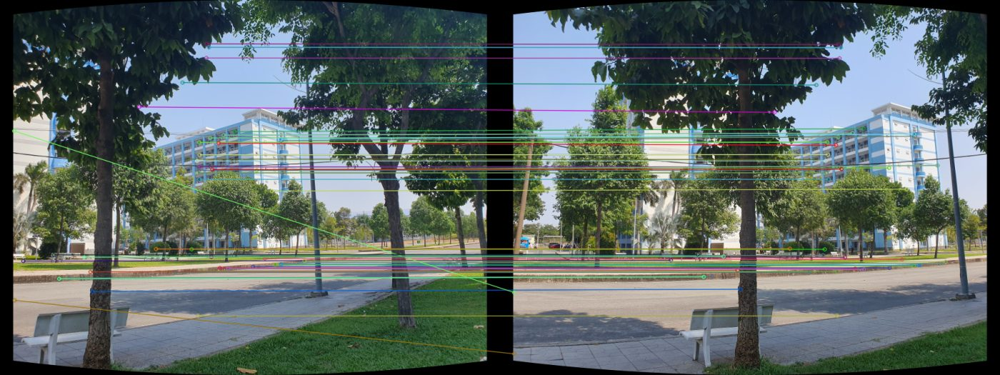

**SIFT — cặp 1→2: 347 inlier RANSAC**

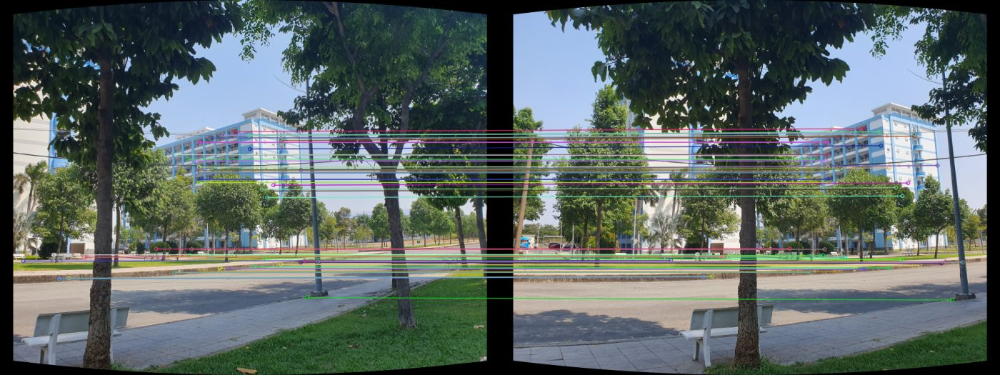

**ORB — cặp 1→2: 576 match sau ratio test**

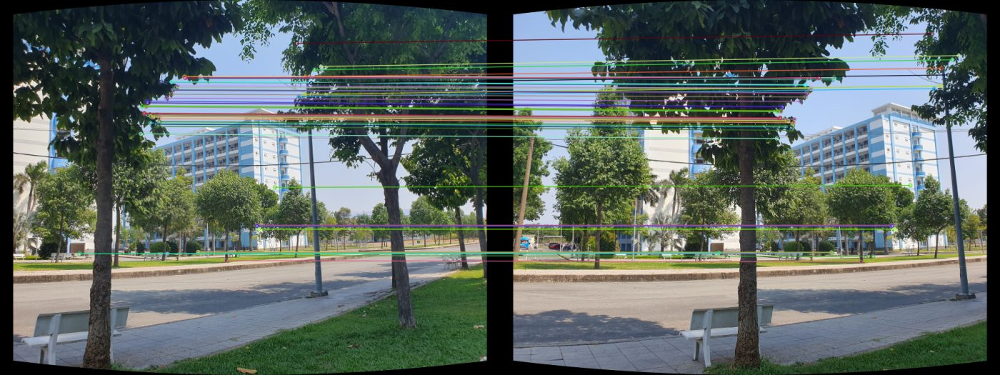

**ORB — cặp 1→2: 493 inlier RANSAC**

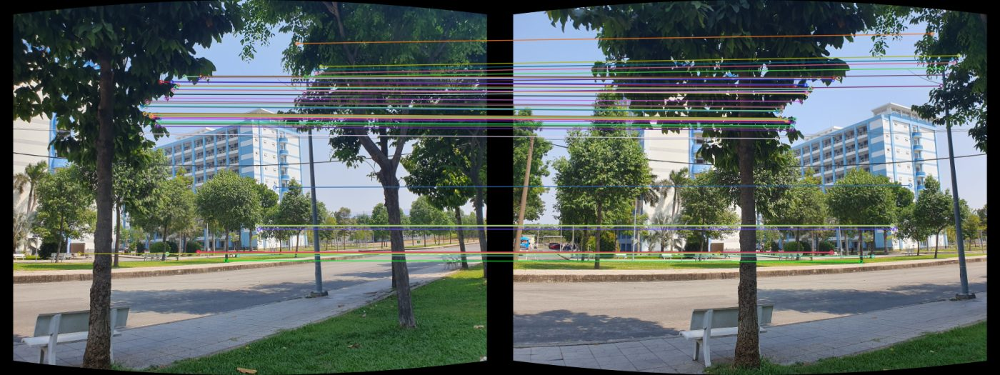

**SURF — cặp 1→2: 380 match sau ratio test**

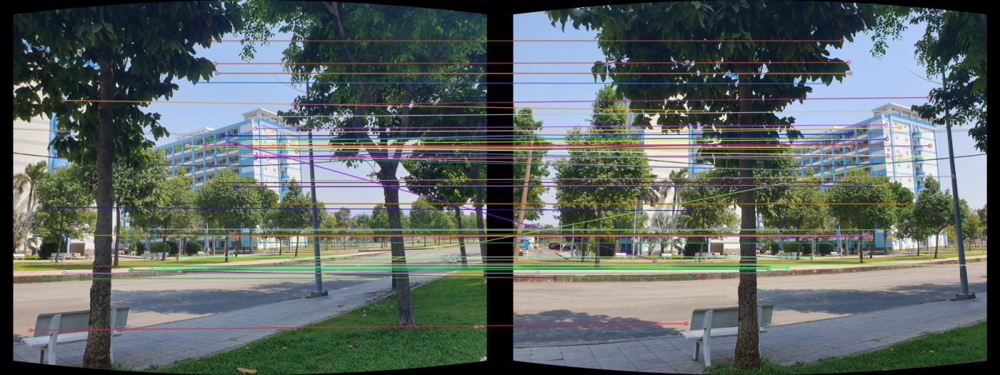

**SURF — cặp 1→2: 165 inlier RANSAC**

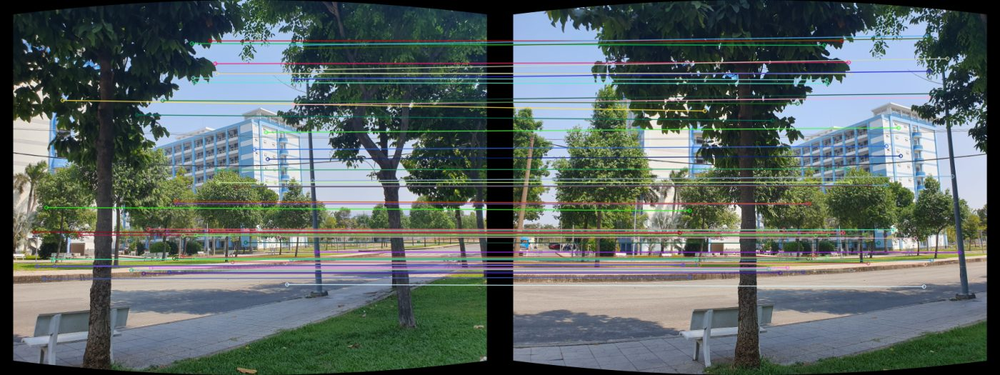

**SIFT — cặp 2→3: 340 match sau ratio test**

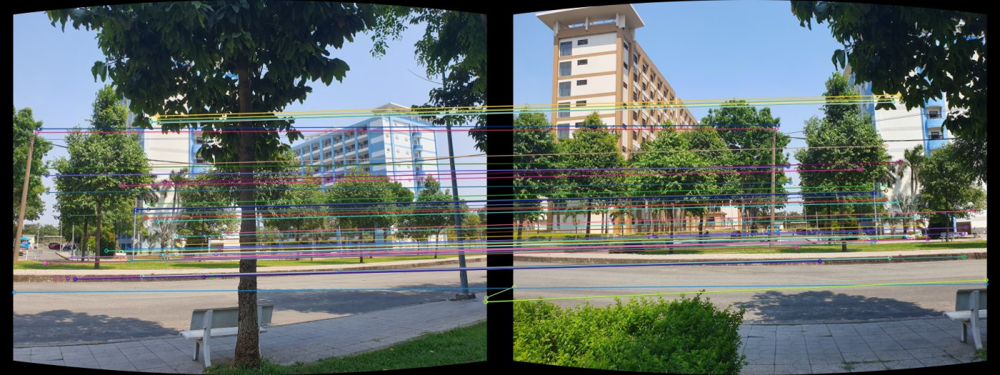

**SIFT — cặp 2→3: 220 inlier RANSAC**

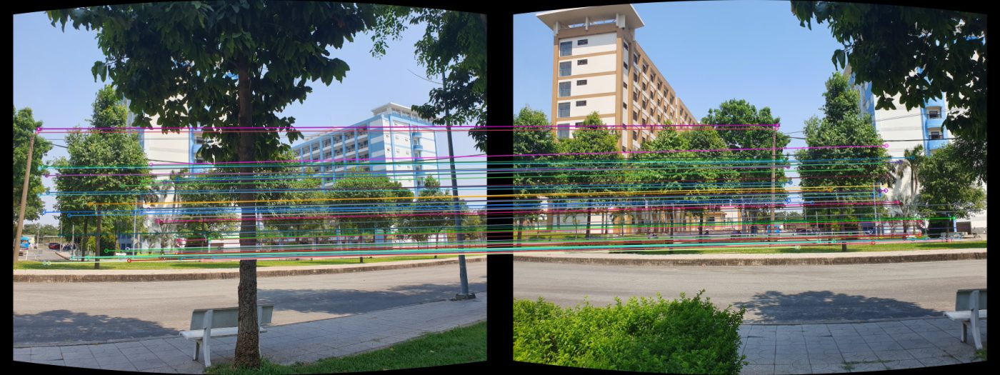

**ORB — cặp 2→3: 275 match sau ratio test**

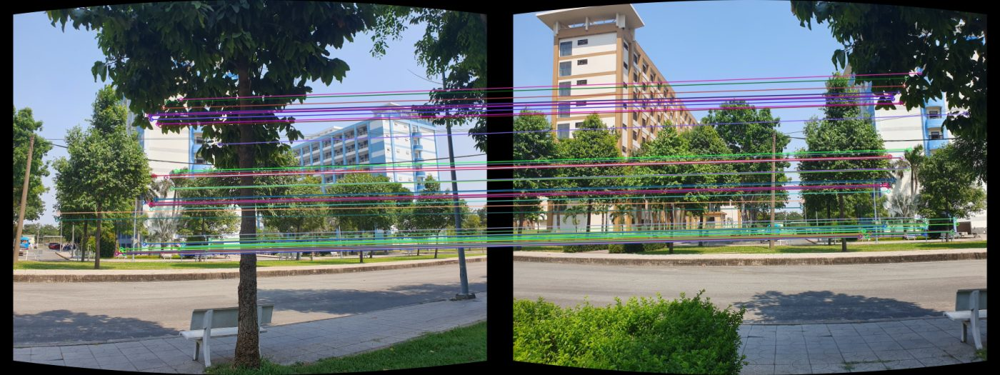

**ORB — cặp 2→3: 151 inlier RANSAC**

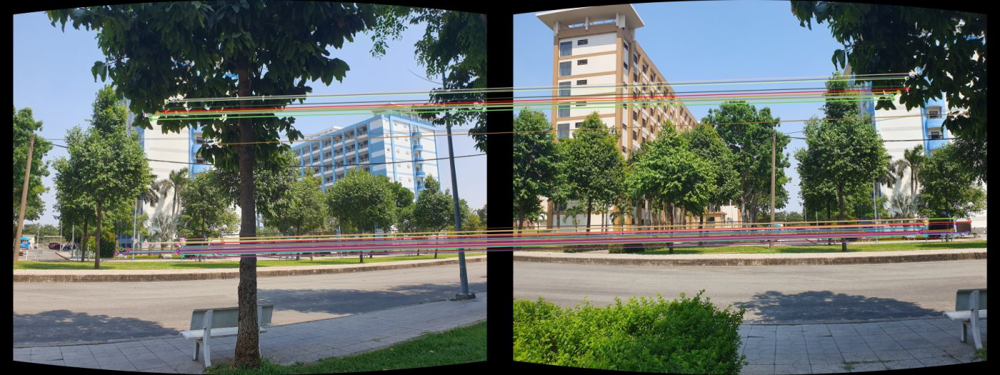

**SURF — cặp 2→3: 236 match sau ratio test**

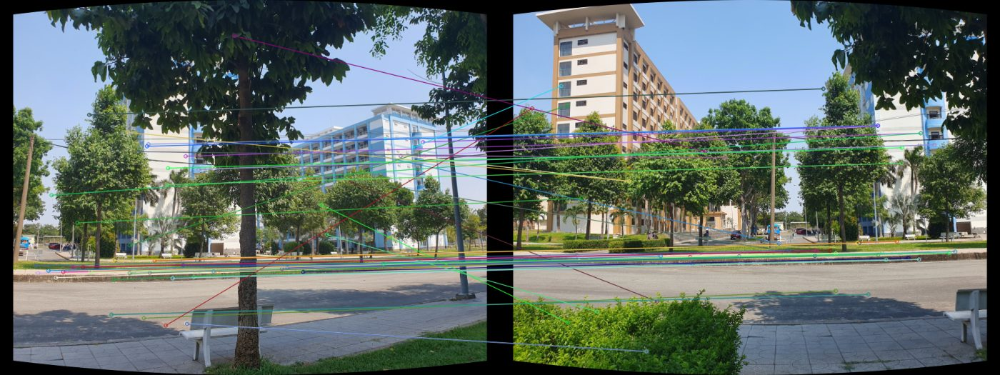

**SURF — cặp 2→3: 83 inlier RANSAC**

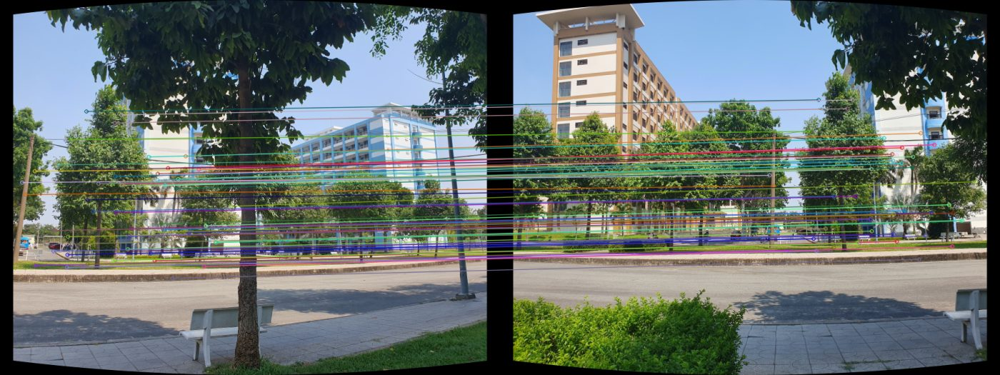

**SIFT — cặp 3→4: 514 match sau ratio test**

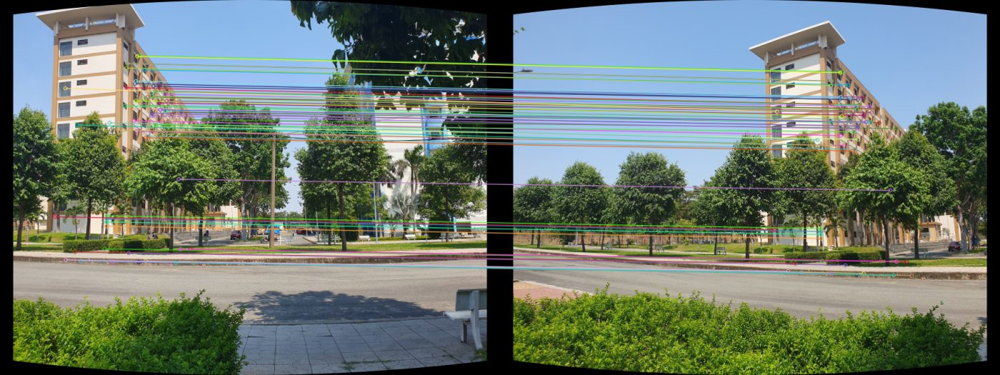

**SIFT — cặp 3→4: 411 inlier RANSAC**

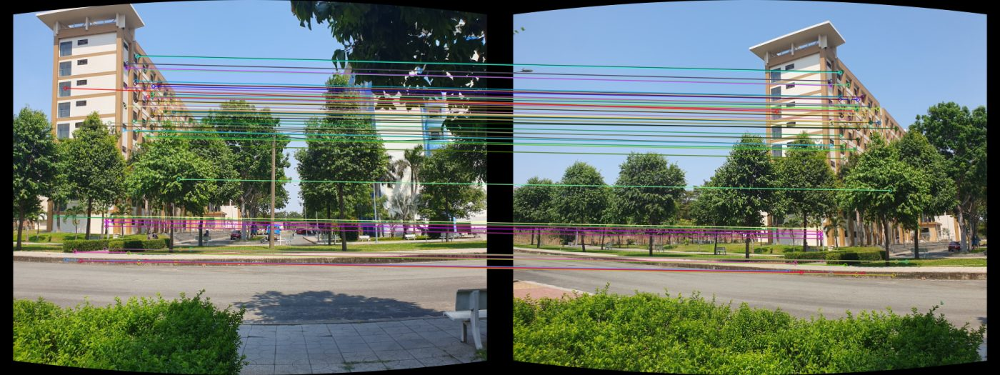

**ORB — cặp 3→4: 345 match sau ratio test**

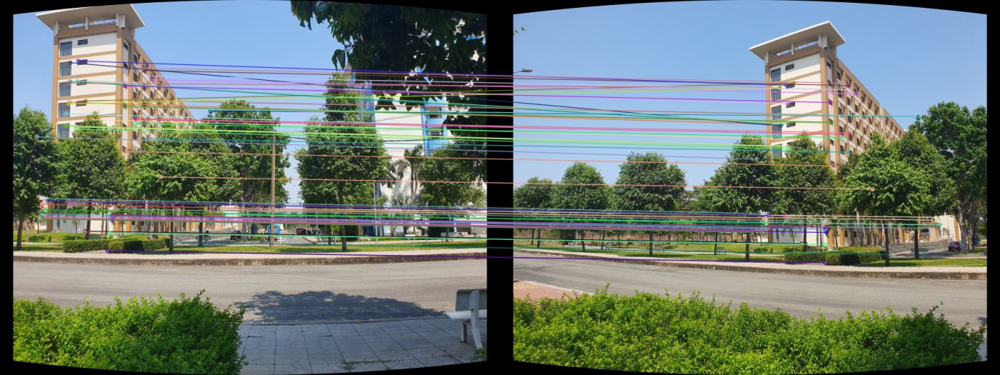

**ORB — cặp 3→4: 298 inlier RANSAC**

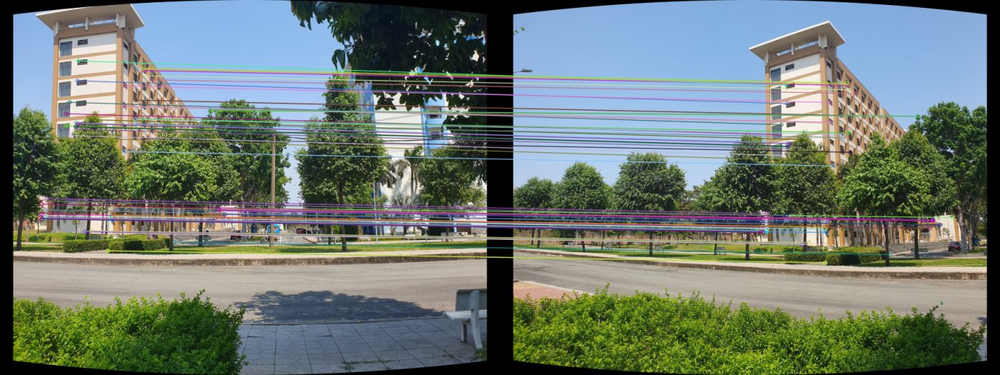

**SURF — cặp 3→4: 288 match sau ratio test**

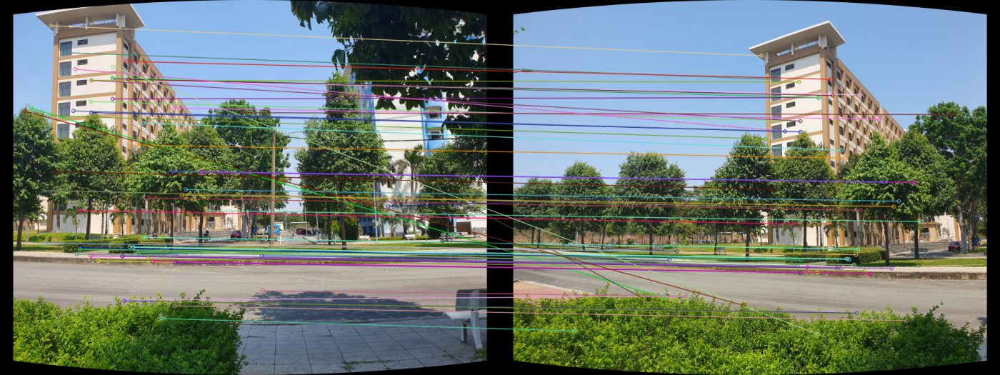

**SURF — cặp 3→4: 139 inlier RANSAC**

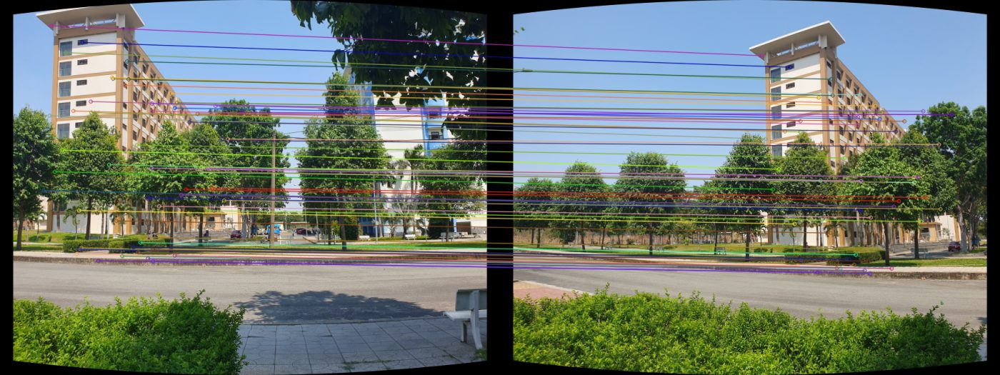

### company

**SIFT — cặp 1→2: 398 match sau ratio test**

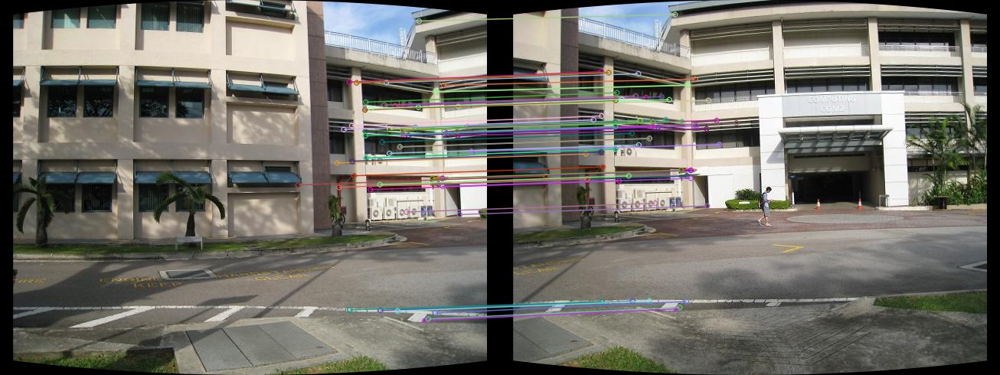

**SIFT — cặp 1→2: 280 inlier RANSAC**

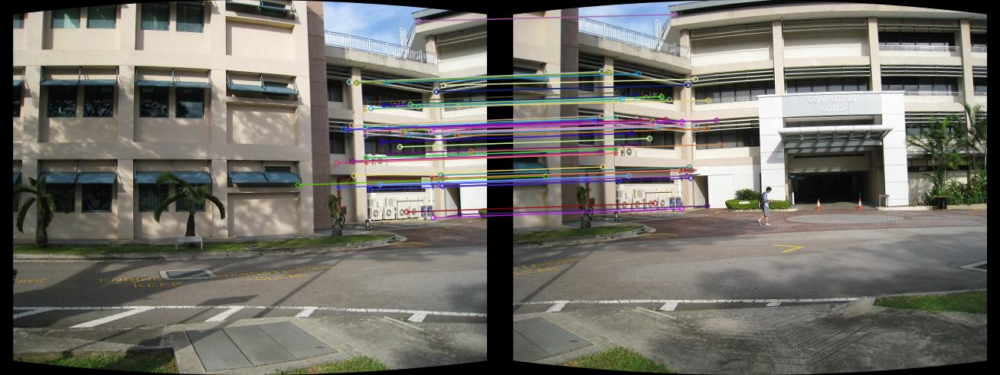

**ORB — cặp 1→2: 671 match sau ratio test**

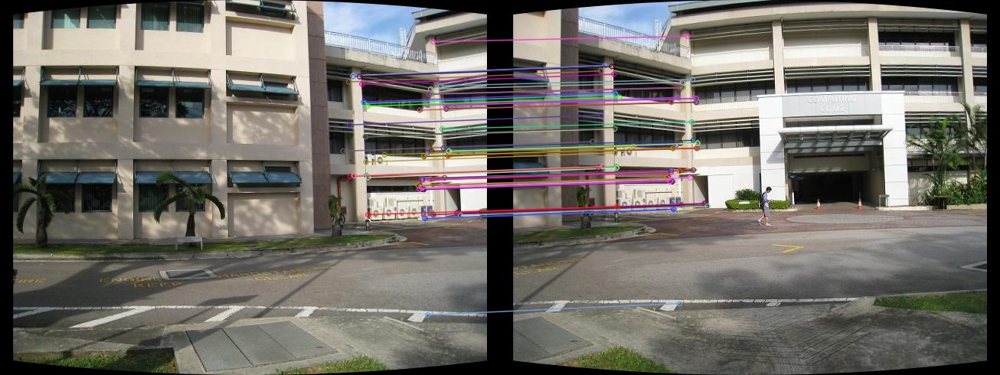

**ORB — cặp 1→2: 588 inlier RANSAC**

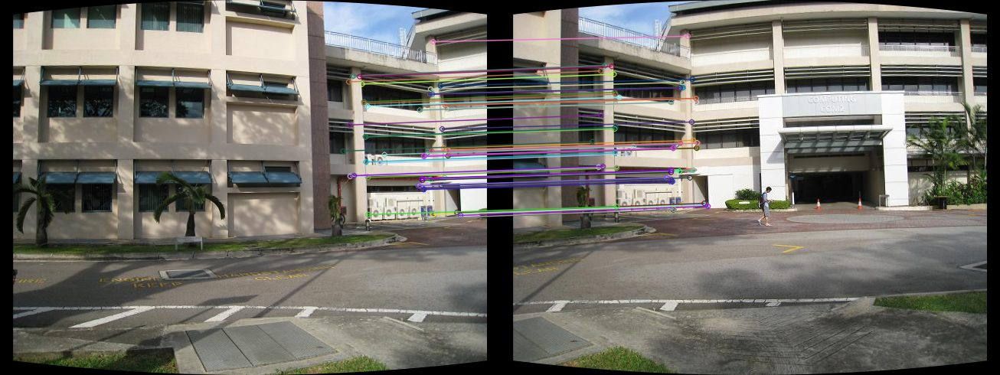

**SURF — cặp 1→2: 356 match sau ratio test**

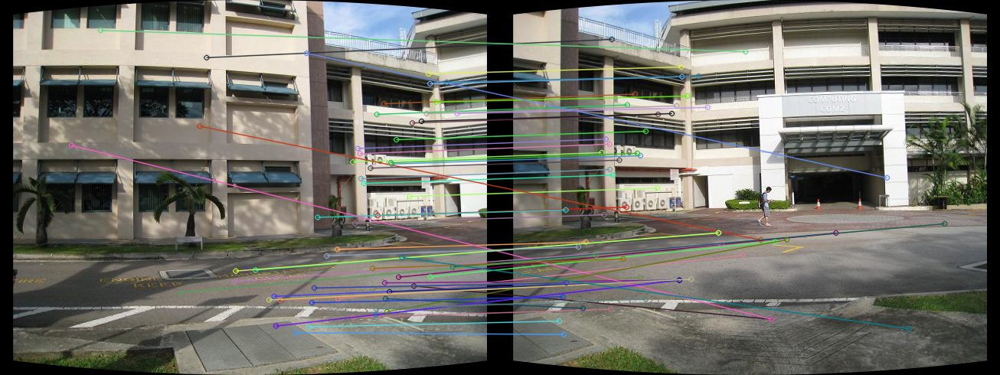

**SURF — cặp 1→2: 164 inlier RANSAC**

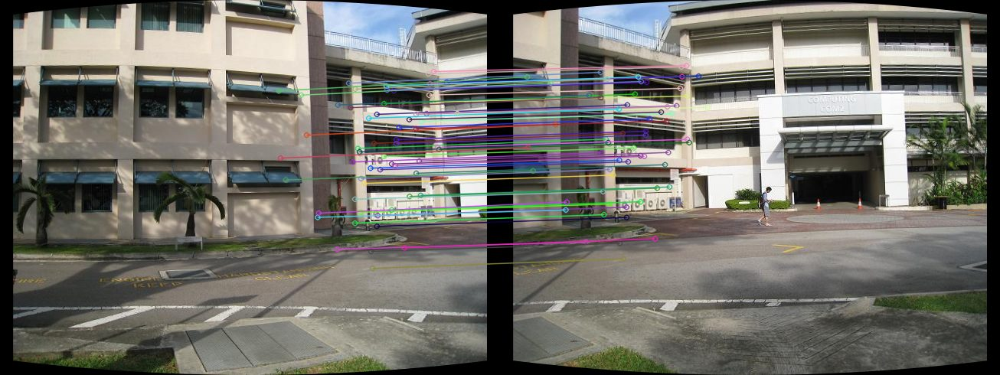

**SIFT — cặp 2→3: 398 match sau ratio test**

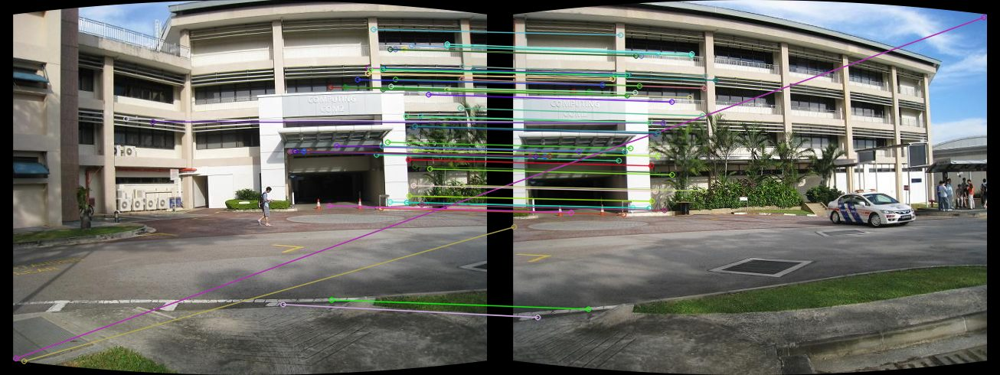

**SIFT — cặp 2→3: 259 inlier RANSAC**

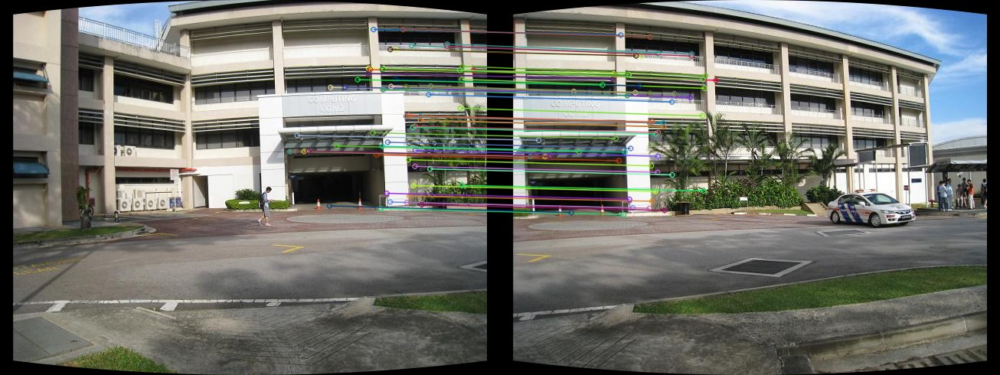

**ORB — cặp 2→3: 477 match sau ratio test**

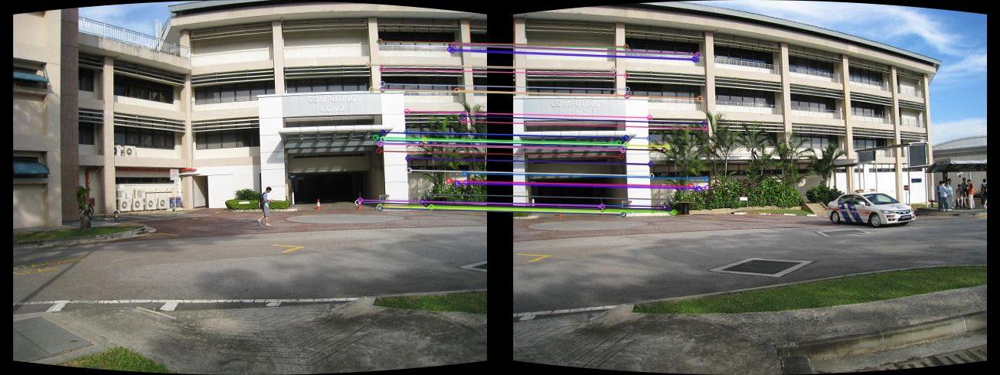

**ORB — cặp 2→3: 358 inlier RANSAC**

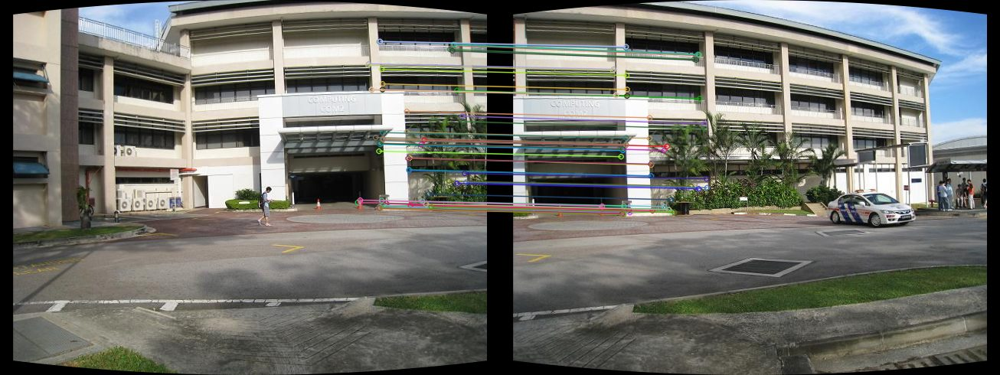

**SURF — cặp 2→3: 349 match sau ratio test**

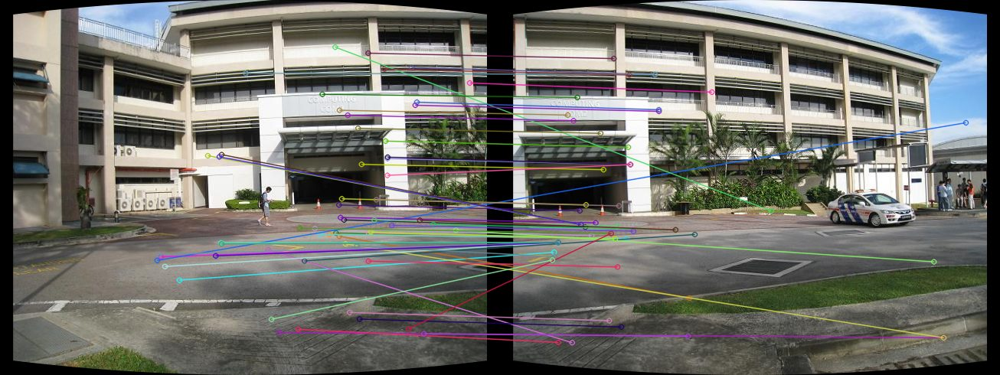

**SURF — cặp 2→3: 101 inlier RANSAC**

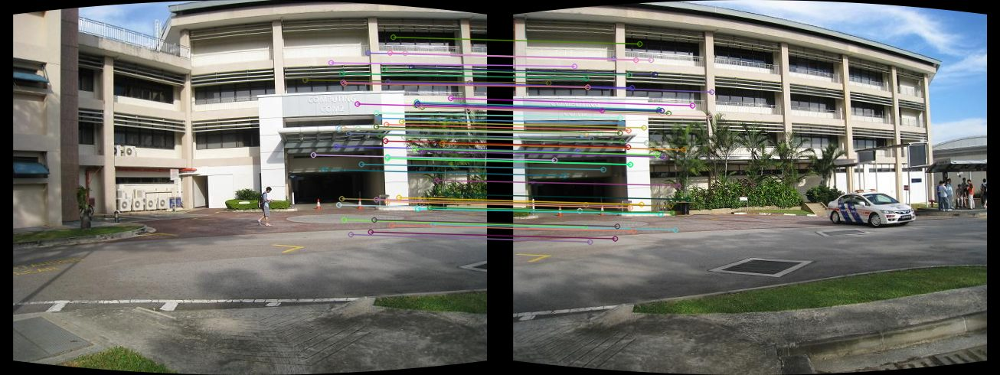

**SIFT — cặp 3→4: 484 match sau ratio test**

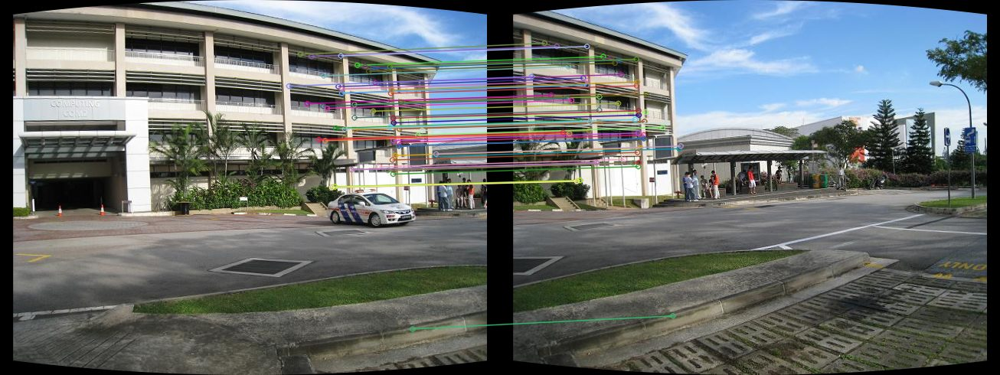

**SIFT — cặp 3→4: 287 inlier RANSAC**

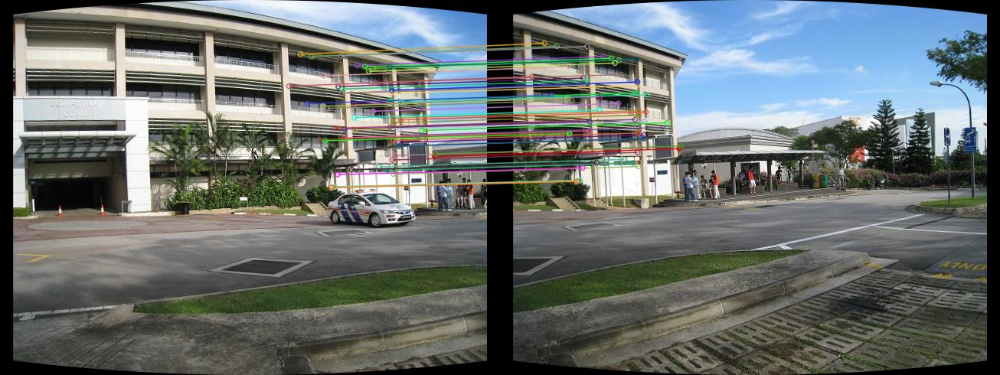

**ORB — cặp 3→4: 677 match sau ratio test**

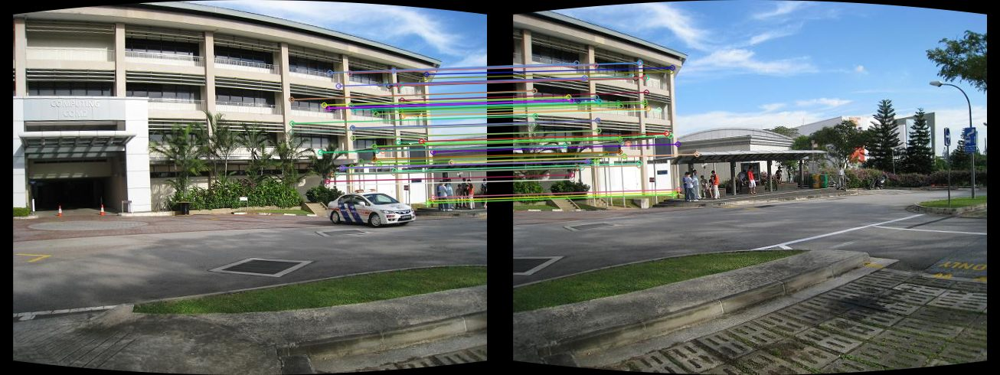

**ORB — cặp 3→4: 577 inlier RANSAC**

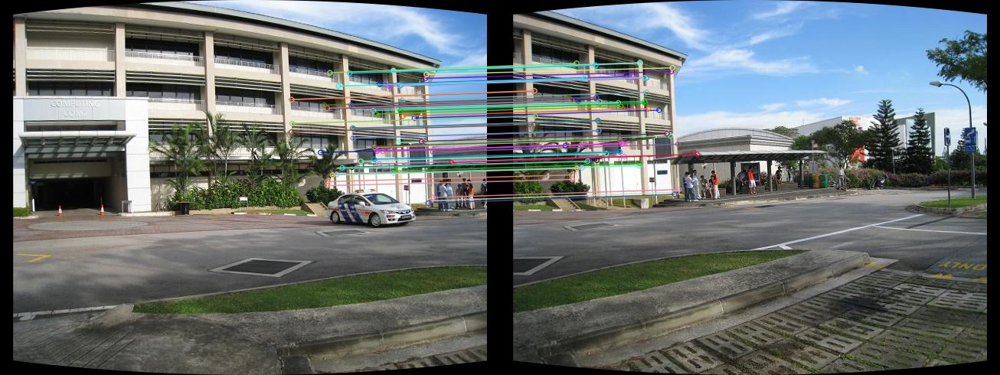

**SURF — cặp 3→4: 408 match sau ratio test**

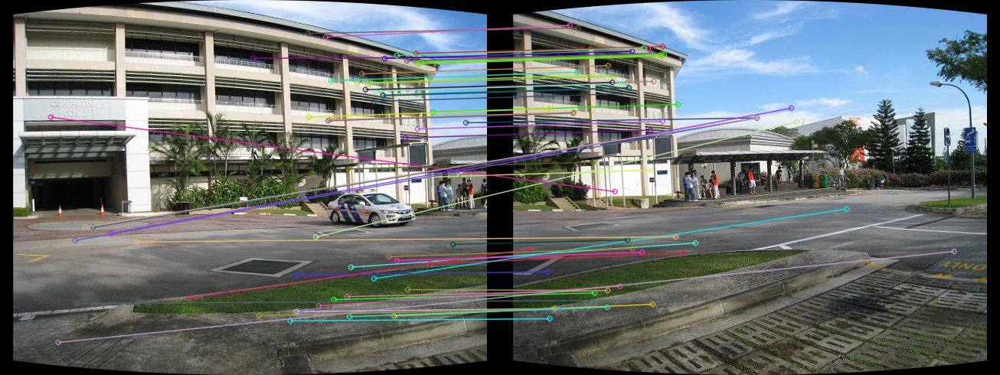

**SURF — cặp 3→4: 152 inlier RANSAC**

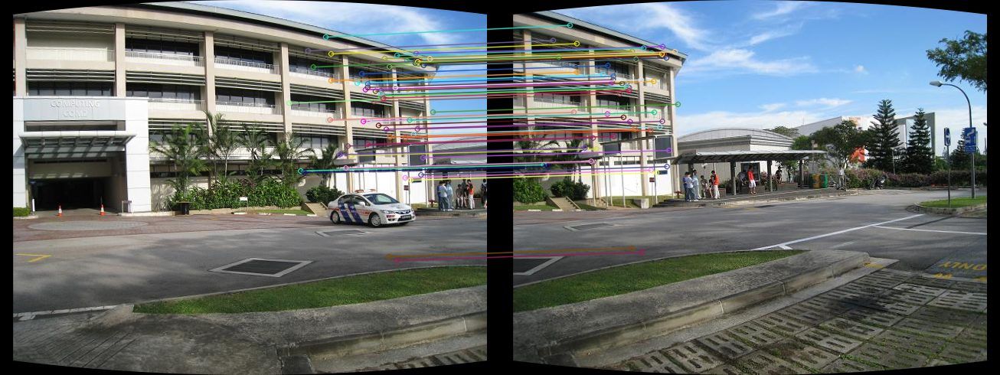

In [26]:
for name, methods in results.items():
    display(Markdown(f"### {name}"))
    for i in range(len(DATASETS[name]) - 1):
        for method, result in methods.items():
            pair = result["pairs"][i]
            n_good = len(pair["matches"])
            n_inliers = int(pair["inliers"].sum())
            show_image(f"{method} — cặp {i+1}→{i+2}: {n_good} match sau ratio test",
                       match_preview(result["images"], result["keypoints"], pair, i))
            show_image(f"{method} — cặp {i+1}→{i+2}: {n_inliers} inlier RANSAC",
                       match_preview(result["images"], result["keypoints"], pair, i, inliers_only=True))


## 8. Kiểm tra căn chỉnh và blending

Overlay chồng từng ảnh lên ảnh kế tiếp với độ trong suốt 50%. Kiểm tra các cạnh tòa nhà, đường, thân cây và vật thể gần máy ảnh để tìm bóng đôi. **Coverage map** biểu thị số ảnh đóng góp vào từng pixel; màu sáng hơn tương ứng nhiều ảnh chồng lấn hơn. Tiếp theo, ảnh **trung bình đều** và ảnh **feather blending** cho thấy tác dụng của xử lý vùng chồng lấn. Blending chỉ làm mềm đường nối; nó không sửa được sai homography hoặc parallax.


### BK-H6

**Overlay SIFT — cặp 1→2**

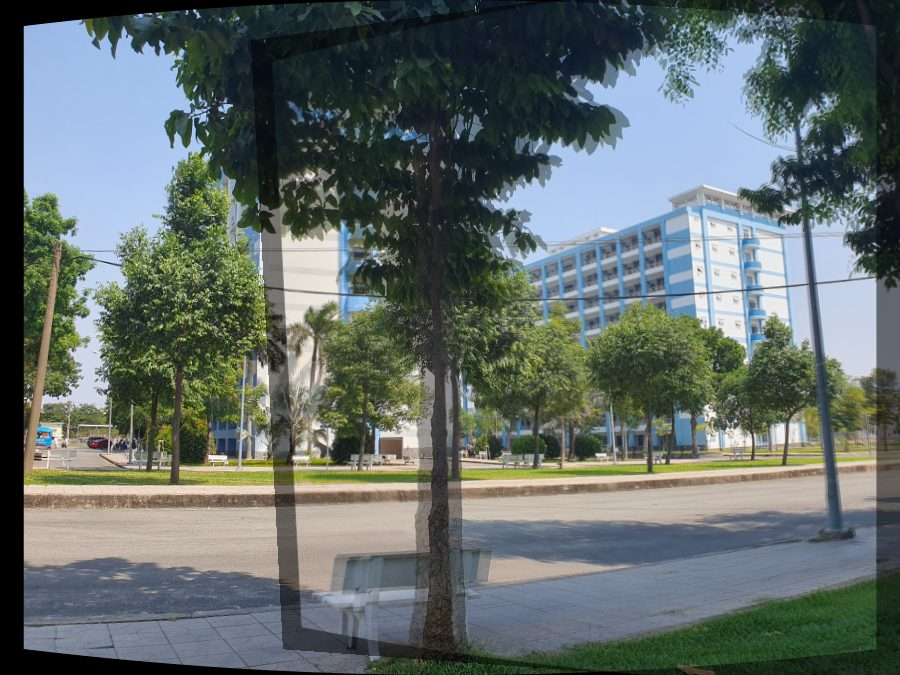

**Overlay ORB — cặp 1→2**

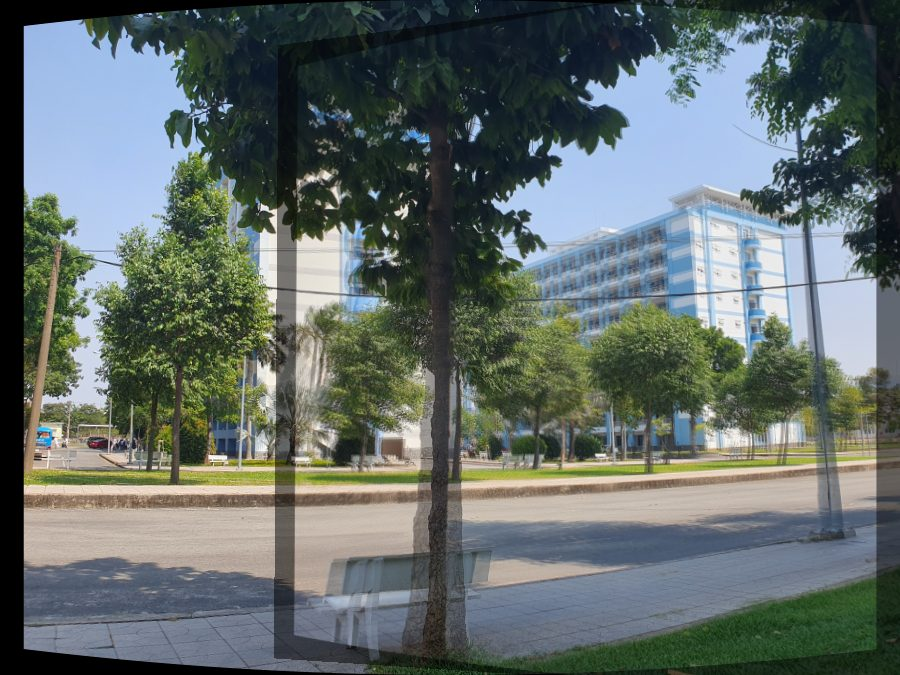

**Overlay SURF — cặp 1→2**

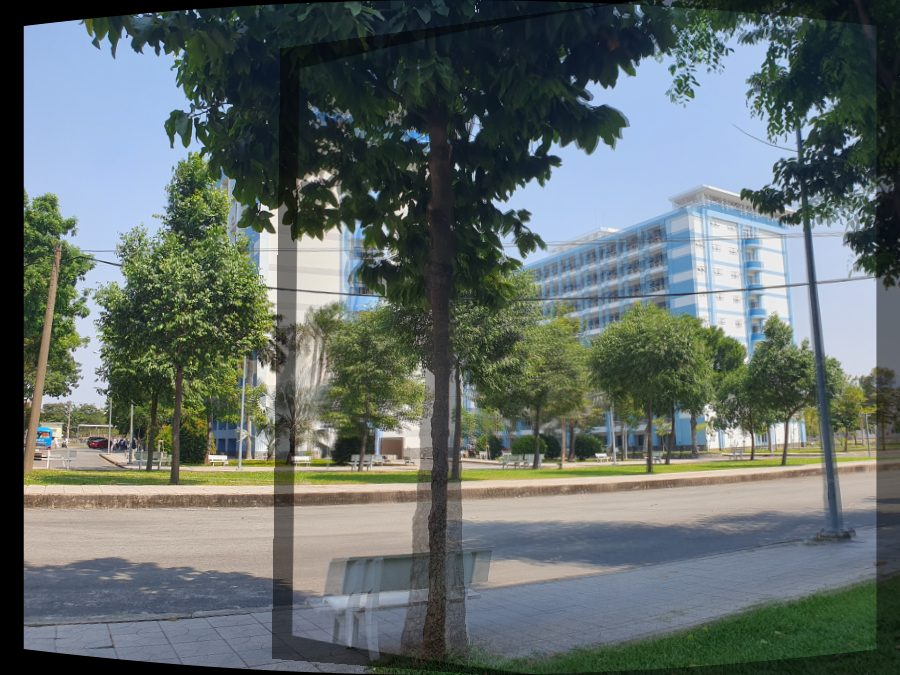

**Overlay SIFT — cặp 2→3**

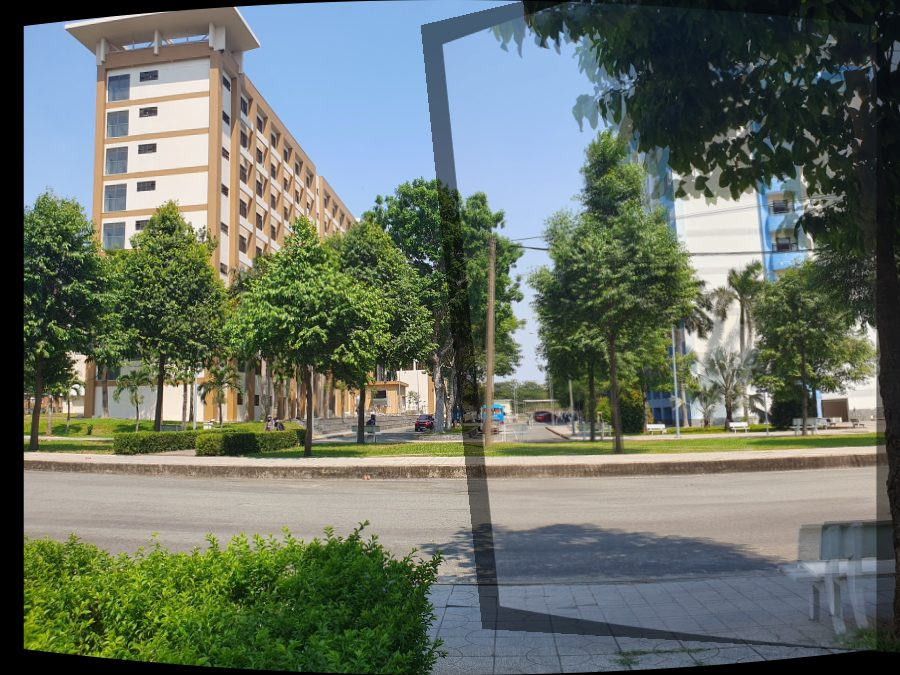

**Overlay ORB — cặp 2→3**

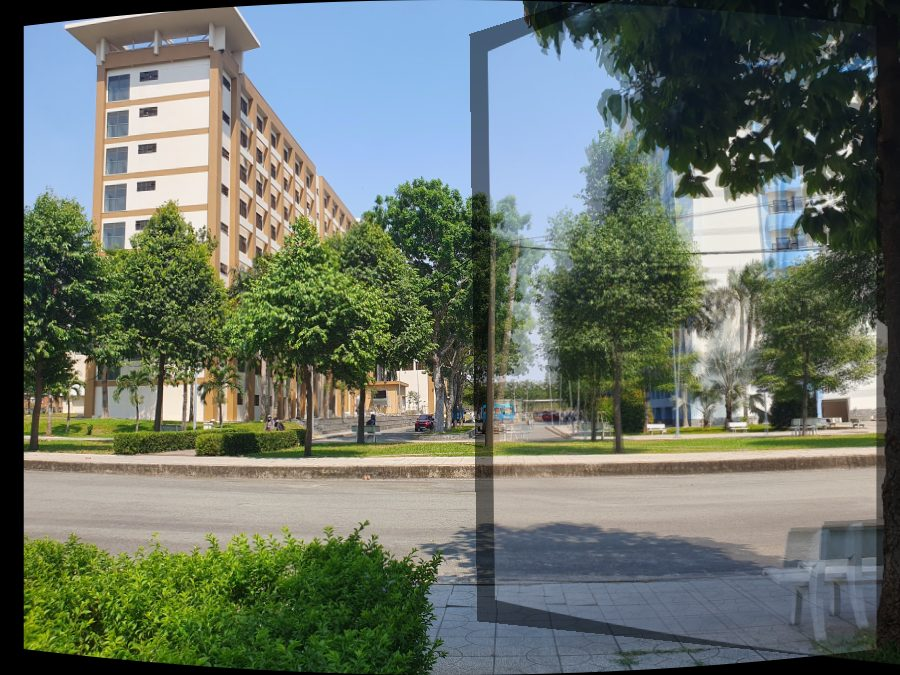

**Overlay SURF — cặp 2→3**

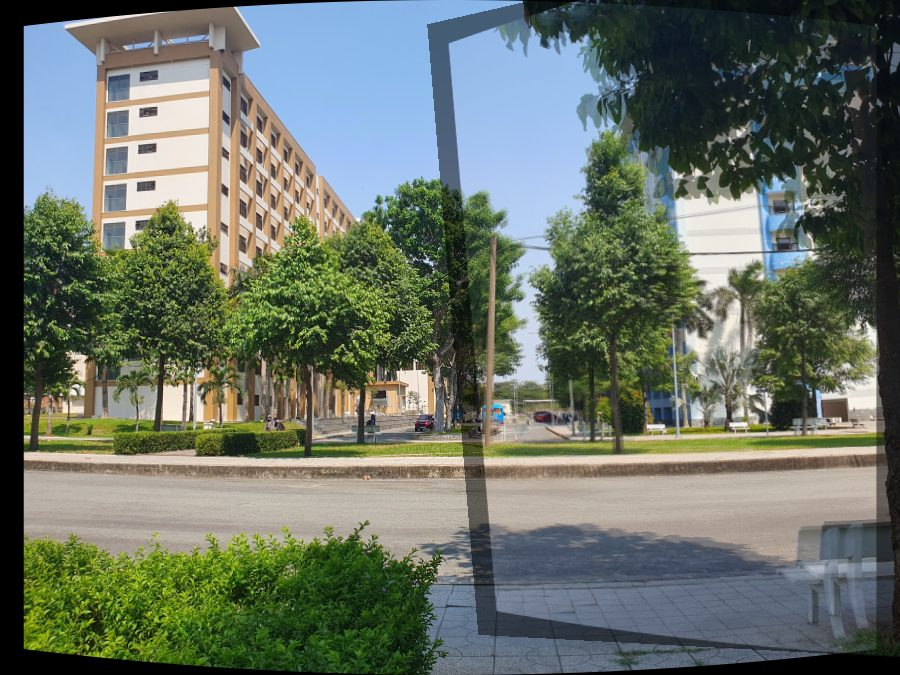

**Overlay SIFT — cặp 3→4**

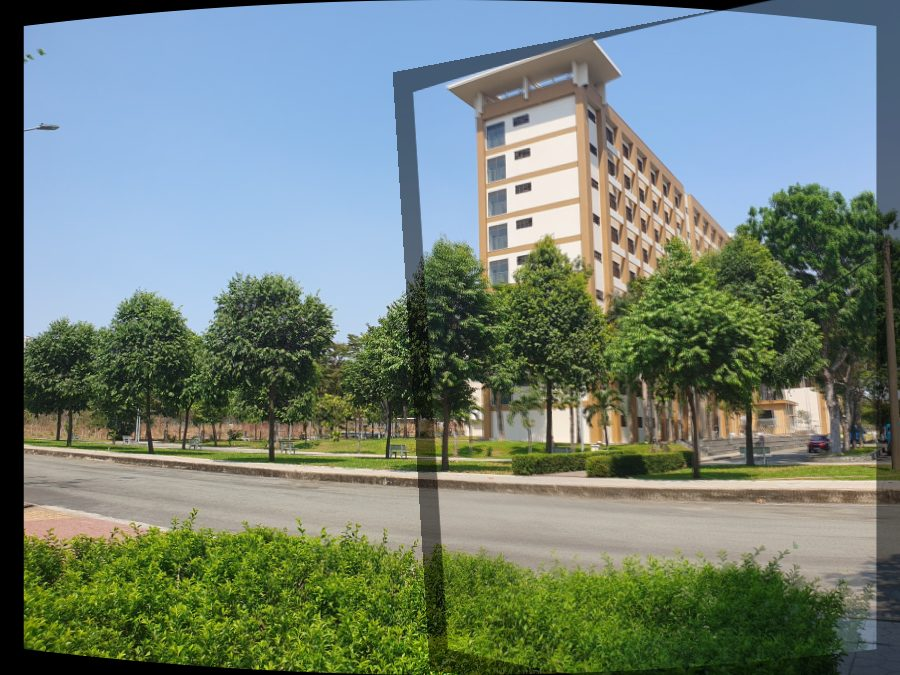

**Overlay ORB — cặp 3→4**

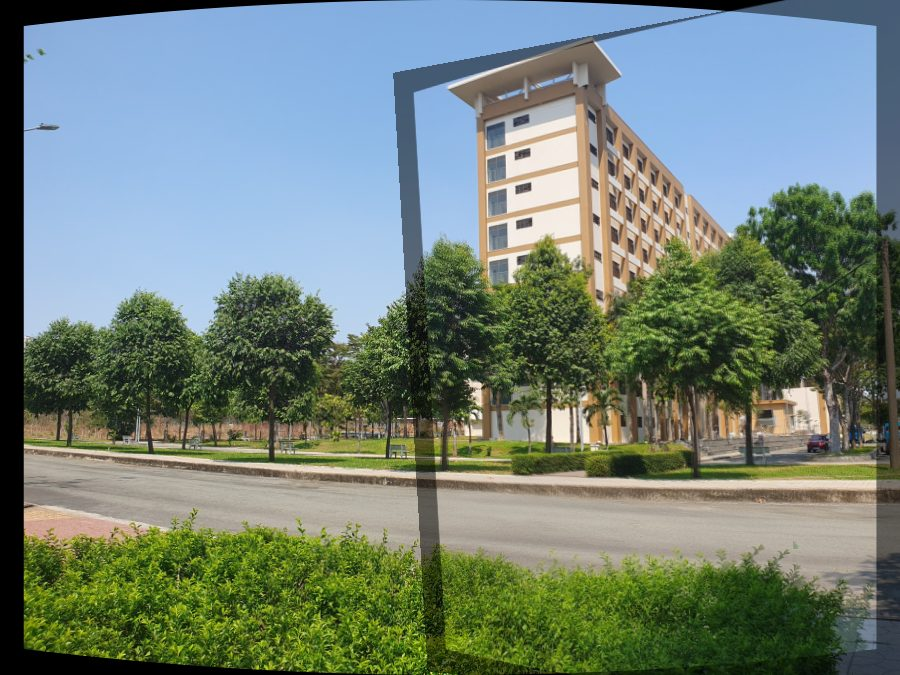

**Overlay SURF — cặp 3→4**

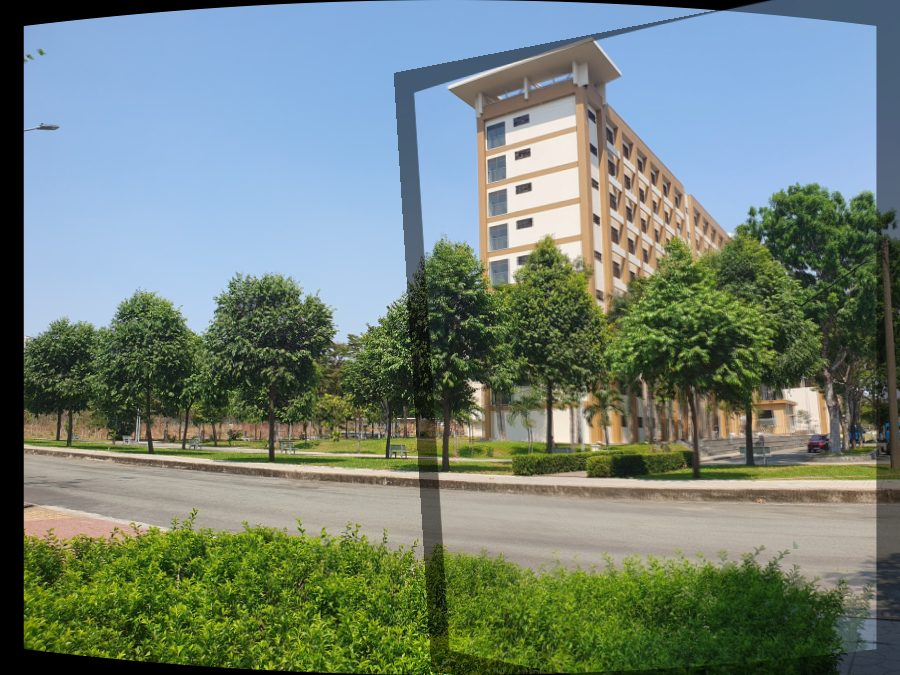

**BK-H6 — SIFT: coverage map**

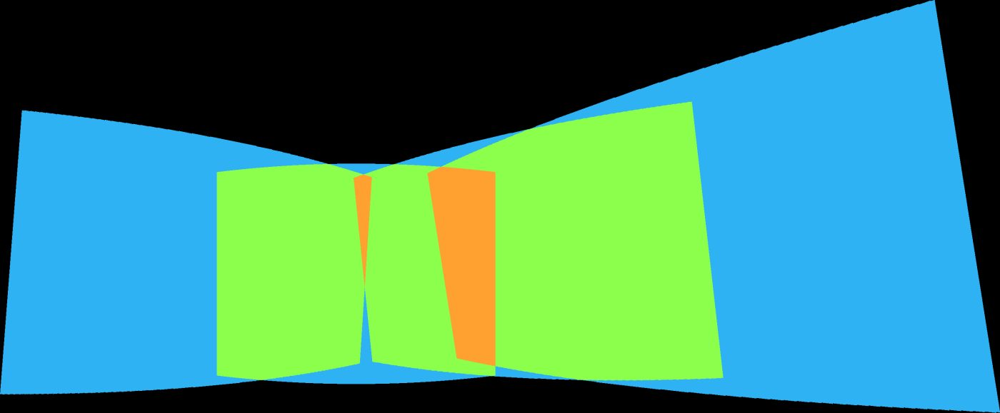

**BK-H6 — SIFT: ghép trung bình đều**

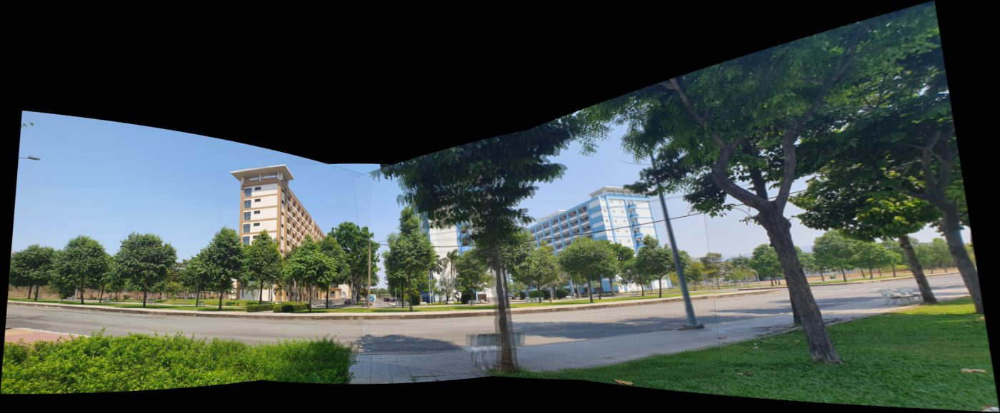

**BK-H6 — SIFT: panorama feather blending**

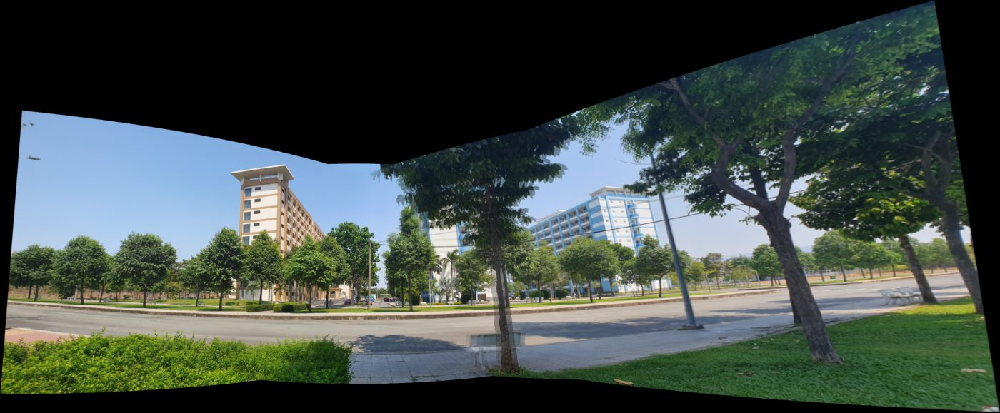

**BK-H6 — ORB: coverage map**

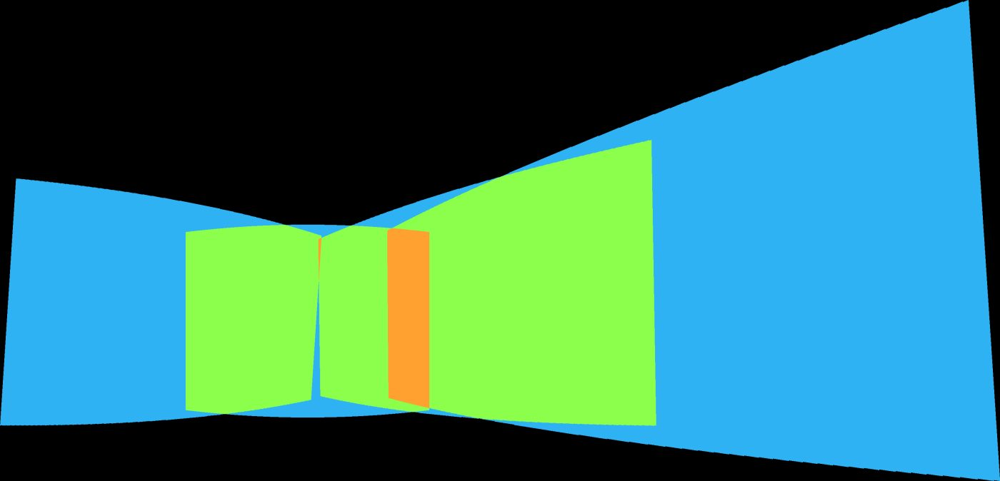

**BK-H6 — ORB: ghép trung bình đều**

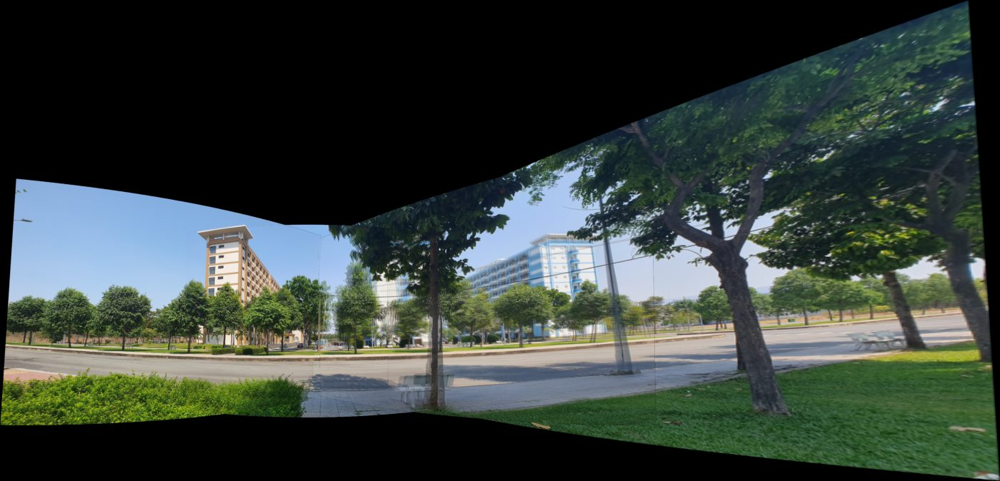

**BK-H6 — ORB: panorama feather blending**

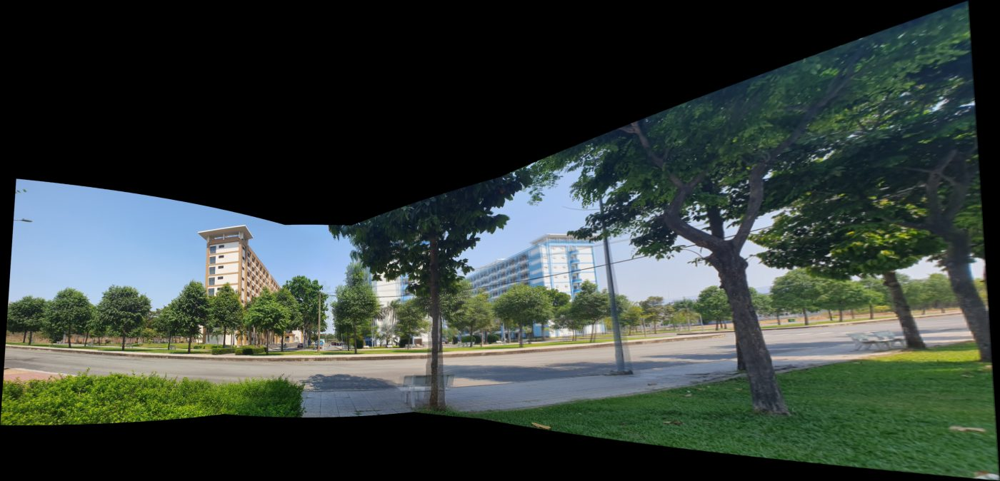

**BK-H6 — SURF: coverage map**

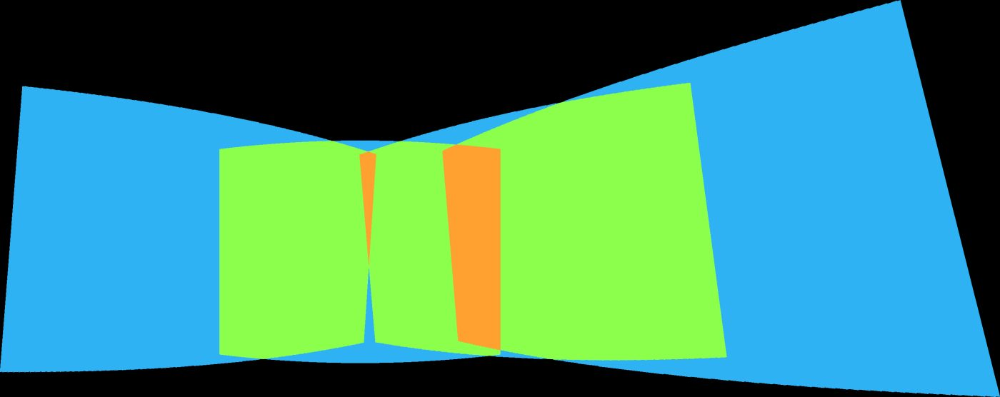

**BK-H6 — SURF: ghép trung bình đều**

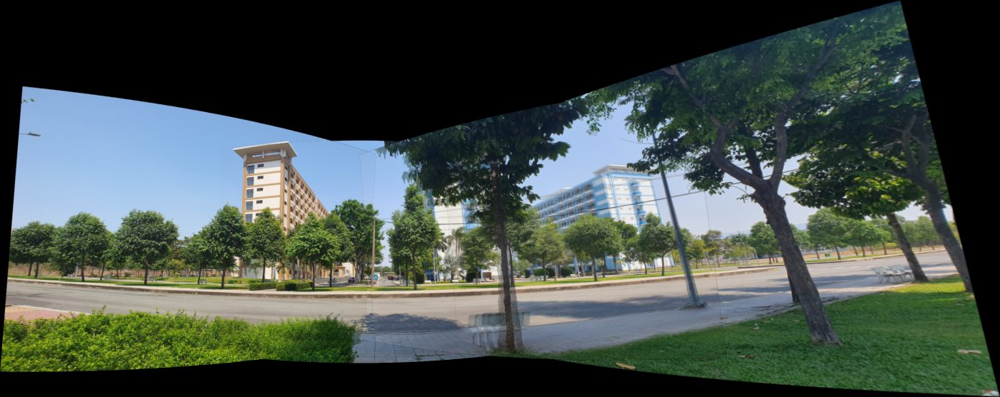

**BK-H6 — SURF: panorama feather blending**

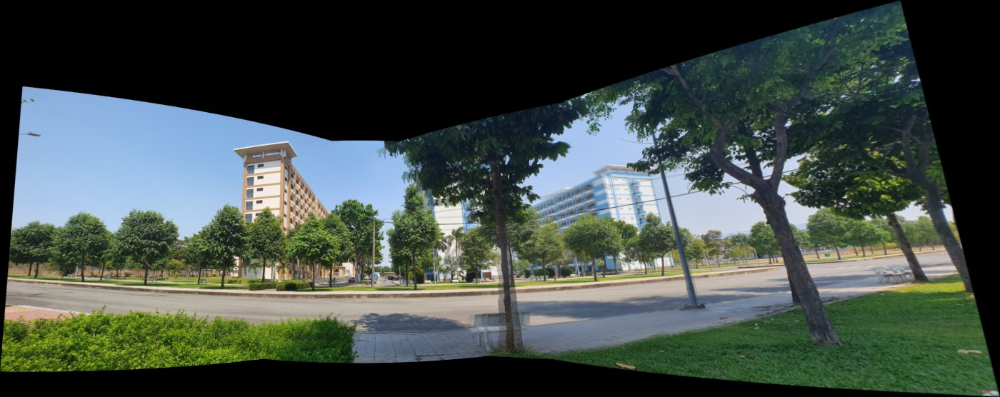

### company

**Overlay SIFT — cặp 1→2**

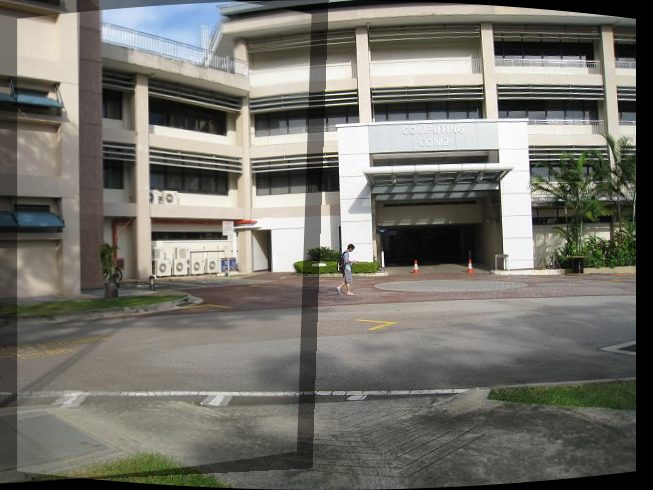

**Overlay ORB — cặp 1→2**

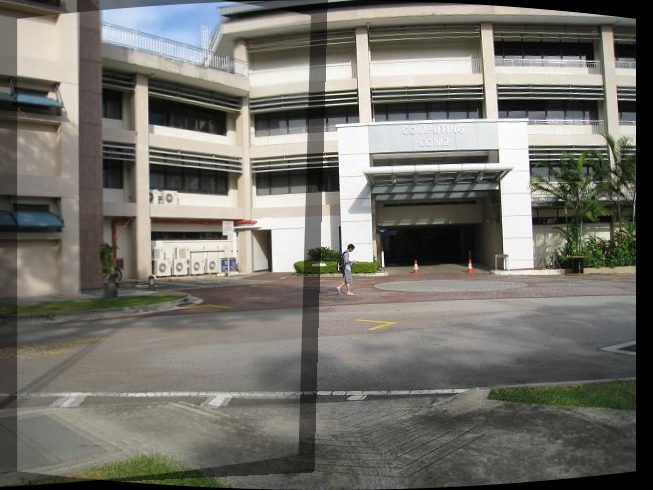

**Overlay SURF — cặp 1→2**

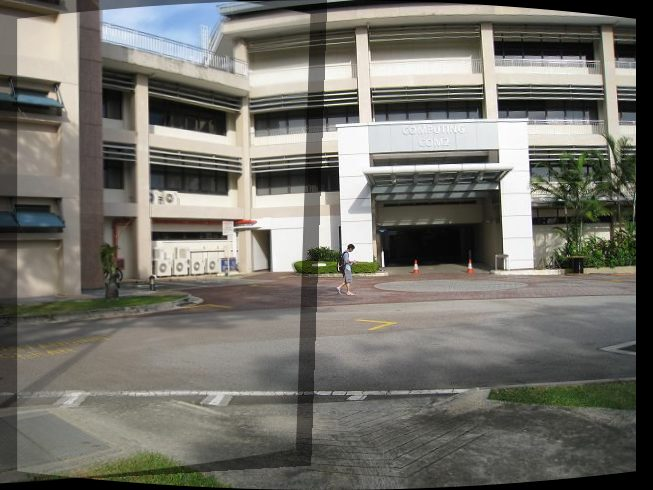

**Overlay SIFT — cặp 2→3**

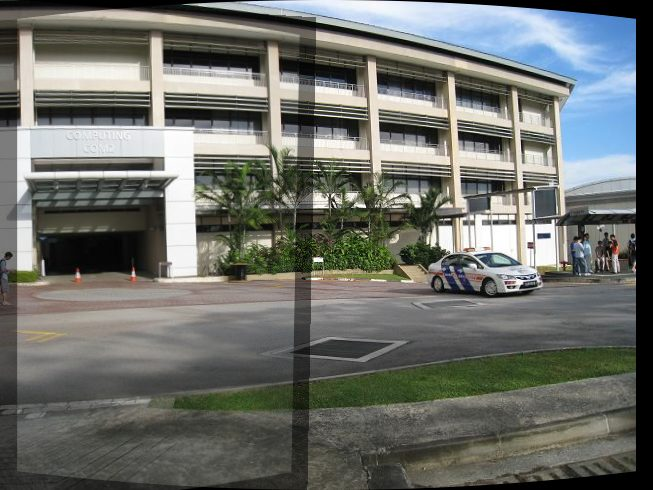

**Overlay ORB — cặp 2→3**

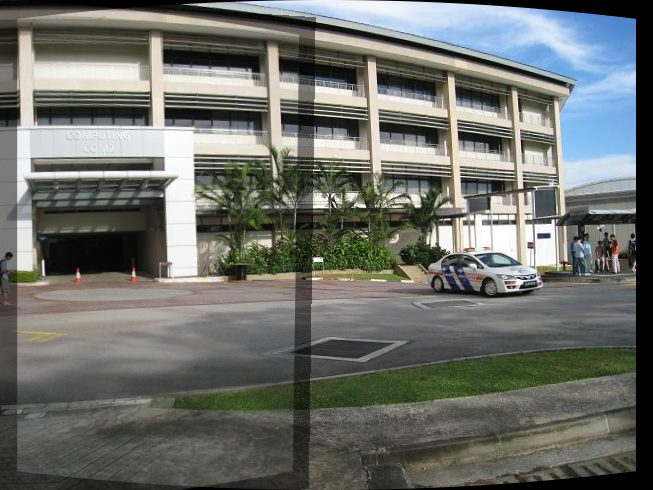

**Overlay SURF — cặp 2→3**

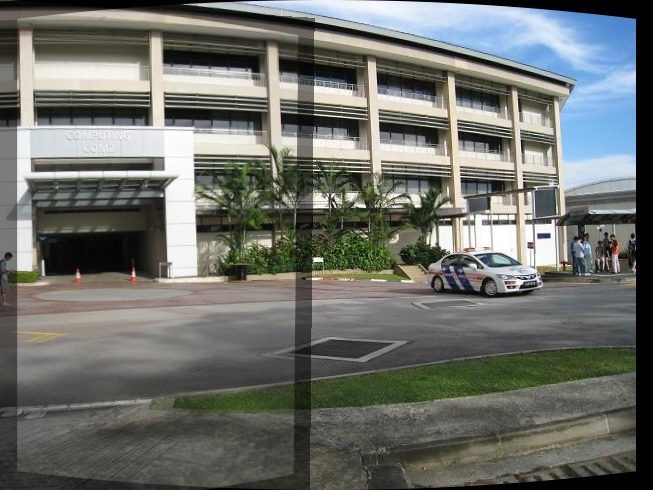

**Overlay SIFT — cặp 3→4**

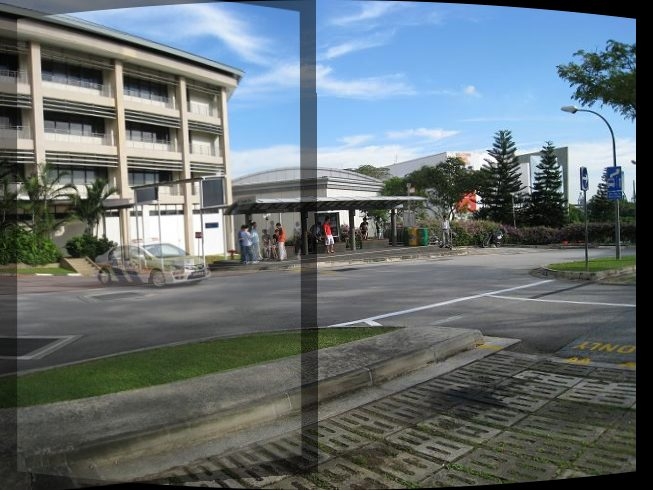

**Overlay ORB — cặp 3→4**

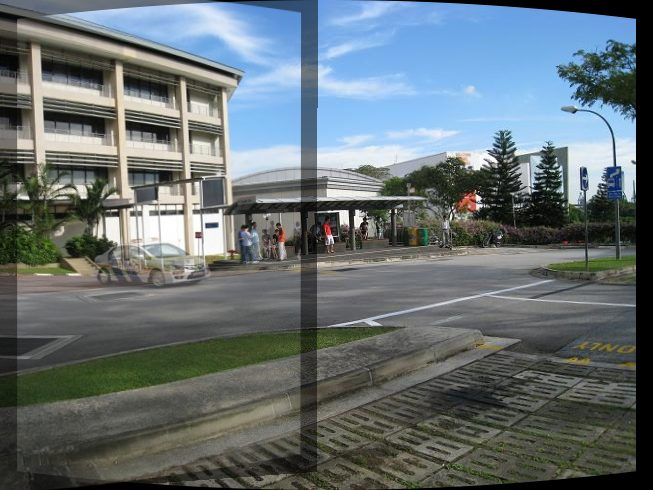

**Overlay SURF — cặp 3→4**

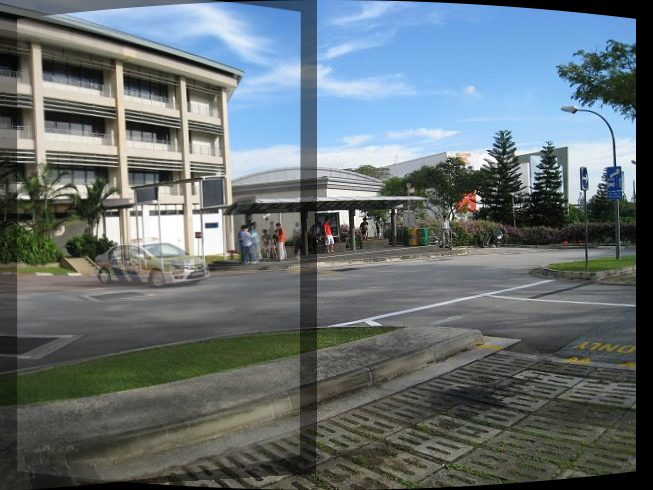

**company — SIFT: coverage map**

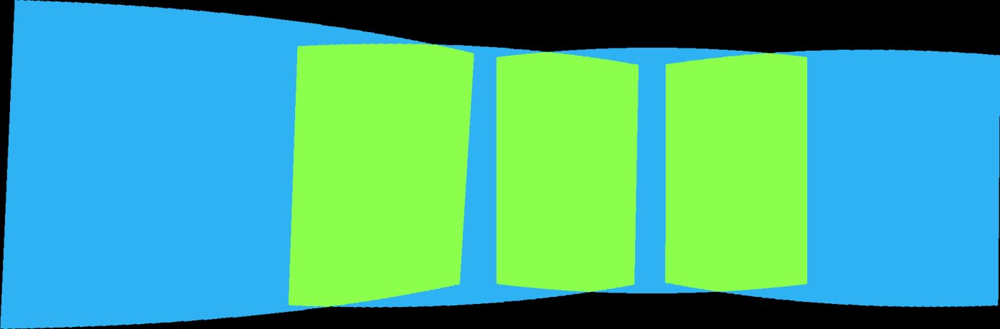

**company — SIFT: ghép trung bình đều**

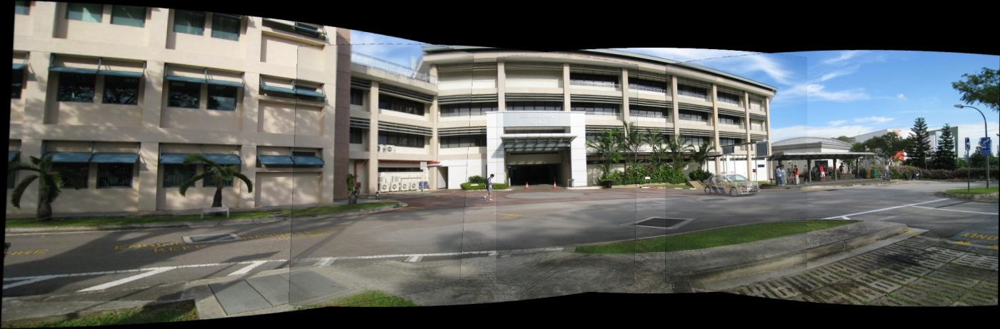

**company — SIFT: panorama feather blending**

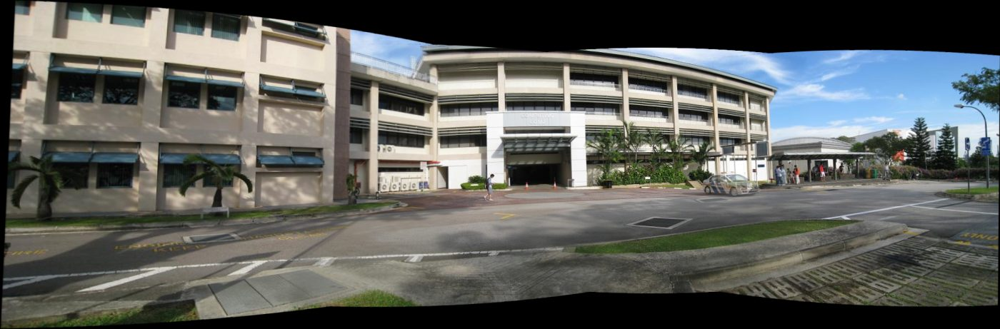

**company — ORB: coverage map**

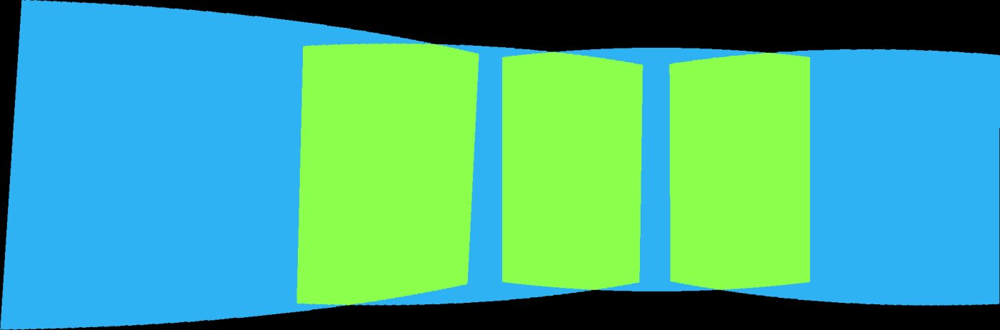

**company — ORB: ghép trung bình đều**

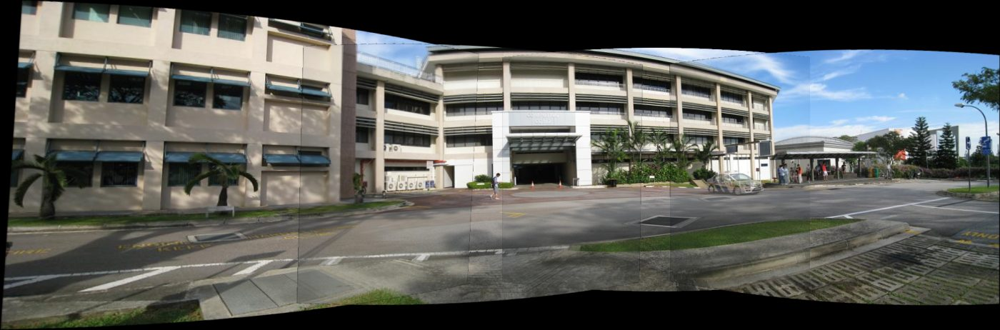

**company — ORB: panorama feather blending**

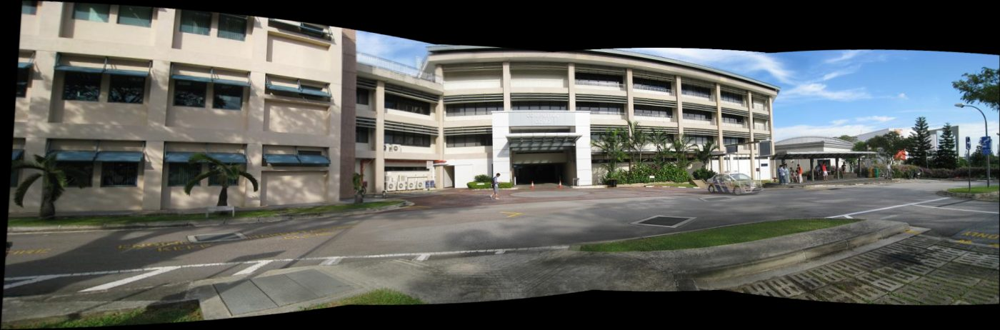

**company — SURF: coverage map**

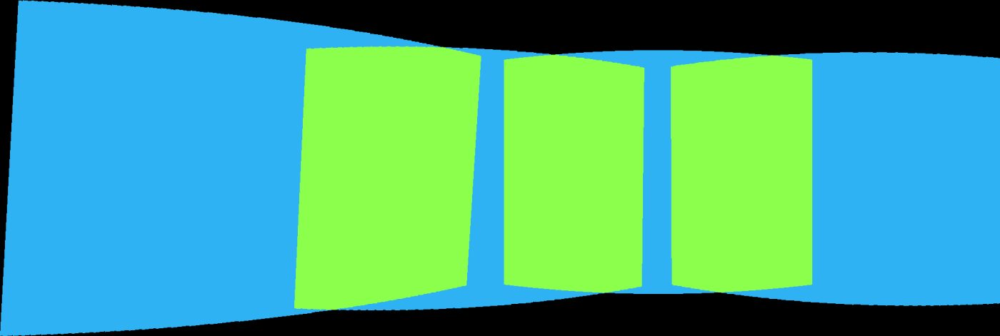

**company — SURF: ghép trung bình đều**

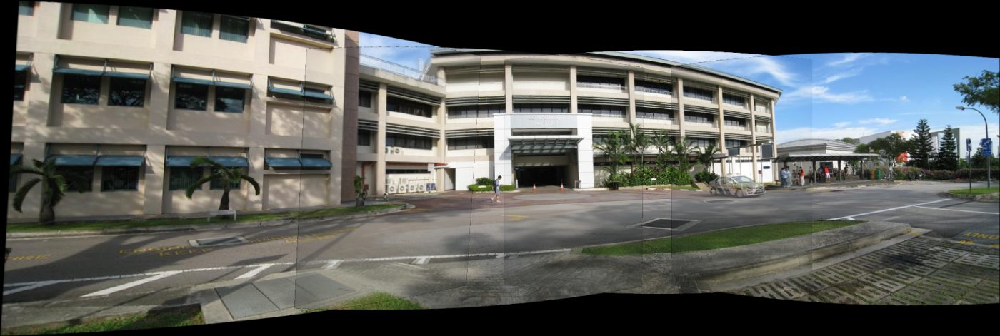

**company — SURF: panorama feather blending**

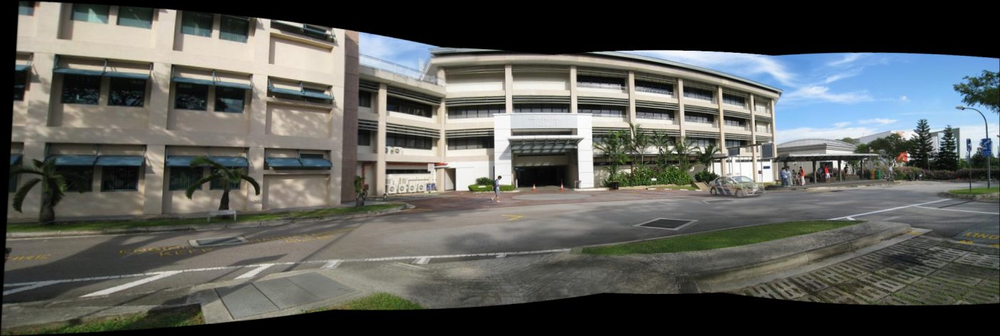

In [27]:
for name, methods in results.items():
    display(Markdown(f"### {name}"))
    for i in range(len(DATASETS[name]) - 1):
        for method, result in methods.items():
            show_image(f"Overlay {method} — cặp {i+1}→{i+2}",
                       pair_overlay(result["images"], result["pairs"][i], i))
    for method, result in methods.items():
        show_image(f"{name} — {method}: coverage map", result["coverage"])
        show_image(f"{name} — {method}: ghép trung bình đều", result["average"])
        show_image(f"{name} — {method}: panorama feather blending", result["panorama"])


## 9. Bảng số liệu và đánh giá

`inlier ratio = inliers / matches sau ratio test`. `median error` là sai số chiếu lại trung vị, tính trên inlier ở kích thước ảnh đã xử lý. Hai chỉ số này mô tả mức nhất quán hình học; chất lượng panorama còn phụ thuộc parallax, vùng chồng lấn và blending. Thời gian chạy có thể thay đổi theo máy và lần chạy.


In [28]:
rows = ["| Bộ ảnh | Phương pháp | Cặp | Keypoint hai ảnh | Match | Inlier | Inlier ratio | Median error (px) |",
        "|---|---|---:|---:|---:|---:|---:|---:|"]
for name, methods in results.items():
    for method, result in methods.items():
        metrics = result["metrics"]
        for i, (matches, inliers, error) in enumerate(zip(
                metrics["matches"], metrics["inliers"], metrics["median_error_px"])):
            points = metrics["keypoints"]
            rows.append(f"| {name} | {method} | {i+1}→{i+2} | {points[i]} / {points[i+1]} | "
                        f"{matches} | {inliers} | {inliers / matches:.1%} | {error:.2f} |")
display(Markdown("\n".join(rows)))

runtime_rows = ["| Bộ ảnh | Phương pháp | Tiền xử lý + trích xuất (s) | Matching + H (s) | Tổng (s) | Panorama (px) |",
                "|---|---|---:|---:|---:|---:|"]
for name, methods in results.items():
    for method, result in methods.items():
        m = result["metrics"]
        height, width = result["panorama"].shape[:2]
        runtime_rows.append(f"| {name} | {method} | {m['feature_seconds']:.2f} | "
                            f"{m['geometry_seconds']:.2f} | {m['total_seconds']:.2f} | {width}×{height} |")
display(Markdown("\n".join(runtime_rows)))


| Bộ ảnh | Phương pháp | Cặp | Keypoint hai ảnh | Match | Inlier | Inlier ratio | Median error (px) |
|---|---|---:|---:|---:|---:|---:|---:|
| BK-H6 | SIFT | 1→2 | 2498 / 2498 | 611 | 347 | 56.8% | 1.27 |
| BK-H6 | SIFT | 2→3 | 2498 / 2500 | 340 | 220 | 64.7% | 1.06 |
| BK-H6 | SIFT | 3→4 | 2500 / 2499 | 514 | 411 | 80.0% | 1.30 |
| BK-H6 | ORB | 1→2 | 2500 / 2500 | 576 | 493 | 85.6% | 1.58 |
| BK-H6 | ORB | 2→3 | 2500 / 2500 | 275 | 151 | 54.9% | 1.44 |
| BK-H6 | ORB | 3→4 | 2500 / 2500 | 345 | 298 | 86.4% | 1.50 |
| BK-H6 | SURF | 1→2 | 2390 / 2380 | 380 | 165 | 43.4% | 2.05 |
| BK-H6 | SURF | 2→3 | 2380 / 2361 | 236 | 83 | 35.2% | 1.53 |
| BK-H6 | SURF | 3→4 | 2361 / 2350 | 288 | 139 | 48.3% | 1.59 |
| company | SIFT | 1→2 | 1639 / 1564 | 398 | 280 | 70.4% | 0.77 |
| company | SIFT | 2→3 | 1564 / 1875 | 398 | 259 | 65.1% | 0.71 |
| company | SIFT | 3→4 | 1875 / 2317 | 484 | 287 | 59.3% | 0.64 |
| company | ORB | 1→2 | 2494 / 2497 | 671 | 588 | 87.6% | 1.11 |
| company | ORB | 2→3 | 2497 / 2500 | 477 | 358 | 75.1% | 1.07 |
| company | ORB | 3→4 | 2500 / 2500 | 677 | 577 | 85.2% | 1.07 |
| company | SURF | 1→2 | 2090 / 2165 | 356 | 164 | 46.1% | 1.41 |
| company | SURF | 2→3 | 2165 / 2220 | 349 | 101 | 28.9% | 1.31 |
| company | SURF | 3→4 | 2220 / 2236 | 408 | 152 | 37.3% | 1.16 |

| Bộ ảnh | Phương pháp | Tiền xử lý + trích xuất (s) | Matching + H (s) | Tổng (s) | Panorama (px) |
|---|---|---:|---:|---:|---:|
| BK-H6 | SIFT | 0.42 | 0.07 | 1.47 | 3058×1264 |
| BK-H6 | ORB | 0.11 | 0.05 | 1.51 | 3496×1683 |
| BK-H6 | SURF | 1.94 | 0.05 | 2.77 | 3031×1204 |
| company | SIFT | 0.23 | 0.05 | 0.55 | 1992×656 |
| company | ORB | 0.06 | 0.05 | 0.37 | 2011×664 |
| company | SURF | 1.06 | 0.08 | 1.42 | 2008×676 |

### Nhận xét từ kết quả thực nghiệm

- **BK-H6:** cả ba phương pháp đều tạo được panorama. Trong lần chạy này, sai số chiếu lại trung vị của SIFT là 1.06–1.30 px, ORB là 1.44–1.58 px và SURF là 1.53–2.05 px. SURF giữ lại 83–165 inlier mỗi cặp; cặp 2→3 là khó nhất. Panorama SURF giữ bố cục gần SIFT, trong khi panorama ORB trải rộng hơn do homography khác nhau. Vùng tòa nhà và cây gần đường nối vẫn có bóng đôi/méo ở cả ba kết quả.
- **company:** cả ba panorama tương đối liên tục ở kiến trúc chính. ORB cho nhiều match/inlier nhất; SIFT có sai số chiếu lại thấp nhất (0.64–0.77 px), kế tiếp là ORB (1.07–1.11 px) và SURF (1.16–1.41 px). SURF có ít inlier hơn nhưng vẫn đủ để ghép được toàn cảnh. Bóng mờ quanh người/xe trong vùng chồng lấn liên quan đến vật thể di chuyển và parallax.
- **Thời gian:** số liệu là thời gian chạy trên máy hiện tại. SURF được tính bởi Mahotas, SIFT/ORB bởi OpenCV, nên chênh lệch thời gian bao gồm khác biệt triển khai thư viện; không nên dùng số đo này làm kết luận tổng quát về tốc độ thuật toán.
- **Vùng đen ngoài panorama:** là phần canvas không có dữ liệu ảnh sau phép chiếu/căn chỉnh. Bounding box hiện tại giữ toàn bộ vùng có dữ liệu, nên vẫn còn các góc đen.

### Cách viết nhận xét trong báo cáo

Với **mỗi bộ ảnh**, đối chiếu panorama SIFT, ORB và SURF ở cùng vị trí: (1) cạnh công trình/đường có thẳng và liên tục không; (2) cây, người, xe hoặc vật thể gần máy có bóng đôi không; (3) độ sáng/màu qua vùng chồng lấn có thay đổi đột ngột không. Dẫn số match, inlier, inlier ratio và thời gian từ bảng trên để giải thích. Không kết luận phương pháp tốt hơn chỉ vì có nhiều keypoint hoặc match hơn: cần ưu tiên căn chỉnh đúng và panorama dễ nhìn. Nếu overlay đã lệch rõ, nguyên nhân thuộc matching/homography; nếu overlay đúng nhưng còn đường nối, cần xem blending hoặc khác biệt phơi sáng.

**Giới hạn:** homography đơn phù hợp khi máy ảnh chủ yếu xoay quanh cùng tâm quan sát hoặc cảnh gần phẳng. Vật thể ở các độ sâu khác nhau có thể gây parallax; feather blending không loại bỏ hoàn toàn hiện tượng này. Notebook giữ cách ghép ở mức cơ bản theo yêu cầu mục 2.2.
